# Scheduling-Delay Evidence Analysis for eBPF Bottleneck Diagnosis

## Purpose

This notebook investigates whether `avg_stall_ns`, interpreted as **average wakeup-to-run scheduling delay**, is associated with meaningfully different independent CPU, memory, I/O, lock, and scheduling/resource behavior.

The analysis is deliberately **not** a model-training exercise. Thresholds are evaluated using distributional evidence, effect sizes, change-point analysis, anomaly analysis, and feature-space structure. Existing classifier results are treated only as prior exploratory evidence.

> **Interpretation rule:** elevated scheduling delay is not, by itself, proof of CPU contention, causality, or a bottleneck.

The data-loading, cleaning, feature engineering, and independent-feature allowlist below are copied from the v7 champion-training pipeline so that this analysis uses the same source structure and feature definitions.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import gc
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from scipy.stats import spearmanr, pearsonr, mannwhitneyu, ks_2samp
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

pd.set_option("display.float_format", "{:.5g}".format)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

PLOT_SAMPLE_MAX = 100_000
THRESHOLD_GRID_N = 100
GROUP_BOOTSTRAP_REPS = 500

STALL_LABEL = "Average wakeup-to-run scheduling delay (ms)"

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 1. Preserve the v7 data pipeline

In [2]:
# Same manually specified source structure as the v7 champion notebook.
CSV_PARTS = [
    "perf_metrics1.csv",
    "perf_metrics2.csv",
    # Add additional parts here when they are part of the same dataset.
]

dfs = []
for path in CSV_PARTS:
    if not os.path.exists(path):
        print(f"SKIPPING (not found): {path}")
        continue
    part = pd.read_csv(path)
    part["source_file"] = path
    dfs.append(part)
    print(f"Loaded {path:<20}: {len(part):>9,} rows")

if not dfs:
    raise FileNotFoundError(
        "None of the CSV_PARTS were found. Place the original CSV files in the notebook working directory."
    )

df_raw = pd.concat(dfs, ignore_index=True)

print(f"\nRaw shape: {df_raw.shape}")
if "session_label" in df_raw.columns:
    print(f"Unique session labels: {df_raw['session_label'].nunique()}")
    print(df_raw["session_label"].value_counts().to_string())

Loaded perf_metrics1.csv   :   526,895 rows
Loaded perf_metrics2.csv   :   250,683 rows

Raw shape: (777578, 45)
Unique session labels: 50
session_label
stream_memory_contention     146855
cache_contention             133428
context_switch_contention    121529
llm_inference                 39621
everything_max                21993
ml_training                   21422
everything_insane             20568
lock_cpu_heavy                11752
cpu_8x                        10213
lock_low                      10112
lock_heavy                     9933
everything_extreme             9705
cpu_mem_io                     9449
cpu_medium                     9261
full_system                    8964
cpu_low                        8331
cpu_mem_io_heavy               8082
cpu_mem_4x                     8024
cpu_mem_8x                     7969
mem_low                        7914
mem_extreme                    7764
mem_reclaim                    7449
compile_only                   6823
cpu_mem_2x         

In [3]:
# Same v7 cleaning rules. Every exclusion is reported.
df = df_raw.copy()
before = len(df)

required_clean_cols = ["pid", "ctx_switches", "latency_count", "avg_stall_ns"]
missing_required = [c for c in required_clean_cols if c not in df.columns]
if missing_required:
    raise KeyError(f"Required v7 columns missing: {missing_required}")

cleaning_report = []

def report_filter(name, before_n, after_n):
    cleaning_report.append({
        "step": name,
        "rows_before": before_n,
        "rows_after": after_n,
        "removed": before_n - after_n,
        "removed_pct": 100 * (before_n - after_n) / max(before_n, 1),
    })

n = len(df)
df = df[df["pid"] > 0].copy()
report_filter("pid > 0", n, len(df))

n = len(df)
df = df[df["ctx_switches"] > 0].copy()
report_filter("ctx_switches > 0", n, len(df))

n = len(df)
df = df[df["latency_count"] > 0].copy()
report_filter("latency_count > 0", n, len(df))

print(f"Cleaned: {before:,} -> {len(df):,} rows ({before-len(df):,} removed)")
display(pd.DataFrame(cleaning_report))

Cleaned: 777,578 -> 664,256 rows (113,322 removed)


,step,rows_before,rows_after,removed,removed_pct
0,pid > 0,777578,776135,1443,0.18558
1,ctx_switches > 0,776135,727699,48436,6.2407
2,latency_count > 0,727699,664256,63443,8.7183


In [4]:
# Same causal feature engineering as v7.
df["involuntary_ratio"]  = df["involuntary_switches"] / df["ctx_switches"].clip(lower=1)
df["voluntary_ratio"]    = df["voluntary_switches"] / df["ctx_switches"].clip(lower=1)
df["runtime_per_switch"] = df["total_runtime_ns"] / df["ctx_switches"].clip(lower=1)
df["read_write_ratio"]   = df["read_bytes"] / (df["write_bytes"] + 1)
df["io_bytes_total"]     = df["read_bytes"] + df["write_bytes"]
df["alloc_pressure"]     = df["total_alloc_bytes"] / df["ctx_switches"].clip(lower=1)
df["lock_pressure"] = (
    df["mutex_contentions"] +
    df["rwsem_read_contentions"] +
    df["rwsem_write_contentions"]
)

log_cols = [
    "total_runtime_ns",
    "avg_syscall_latency_ns",
    "max_syscall_latency_ns",
    "io_bytes_total",
    "total_alloc_bytes",
]
for col in log_cols:
    if col in df.columns:
        df[f"log_{col}"] = np.log1p(df[col])

LEAKY_COLS = {
    "avg_stall_ns", "stall_ns", "max_stall_ns", "latency_count",
    "stall_per_switch", "log_stall_ns", "log_avg_stall_ns",
    "log_max_stall_ns", "stall_spike", "log_stall_spike",
}

ALLOWED_FEATURES = [
    "ctx_switches", "cpu_migrations", "involuntary_switches", "voluntary_switches",
    "involuntary_ratio", "voluntary_ratio", "avg_runq_ratio", "runtime_per_switch",
    "minor_faults", "major_faults", "kmalloc_count", "kfree_count",
    "total_alloc_bytes", "alloc_pressure",
    "read_count", "write_count", "read_bytes", "write_bytes", "read_write_ratio", "io_bytes_total",
    "mutex_contentions", "avg_mutex_wait_ns", "rwsem_read_contentions", "rwsem_write_contentions", "lock_pressure",
    "syscall_count", "avg_syscall_latency_ns", "futex_count",
    "log_total_runtime_ns", "log_avg_syscall_latency_ns", "log_max_syscall_latency_ns",
    "log_io_bytes_total", "log_total_alloc_bytes",
]

FEATURE_COLS = [f for f in ALLOWED_FEATURES if f in df.columns]
leakage_check = set(FEATURE_COLS) & LEAKY_COLS
assert not leakage_check, f"LEAKAGE DETECTED: {leakage_check}"

print(f"Feature columns available: {len(FEATURE_COLS)}")
print(FEATURE_COLS)

Feature columns available: 33
['ctx_switches', 'cpu_migrations', 'involuntary_switches', 'voluntary_switches', 'involuntary_ratio', 'voluntary_ratio', 'avg_runq_ratio', 'runtime_per_switch', 'minor_faults', 'major_faults', 'kmalloc_count', 'kfree_count', 'total_alloc_bytes', 'alloc_pressure', 'read_count', 'write_count', 'read_bytes', 'write_bytes', 'read_write_ratio', 'io_bytes_total', 'mutex_contentions', 'avg_mutex_wait_ns', 'rwsem_read_contentions', 'rwsem_write_contentions', 'lock_pressure', 'syscall_count', 'avg_syscall_latency_ns', 'futex_count', 'log_total_runtime_ns', 'log_avg_syscall_latency_ns', 'log_max_syscall_latency_ns', 'log_io_bytes_total', 'log_total_alloc_bytes']


## 2. Data audit

In [5]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_pct": 100 * df.isna().mean(),
    "n_unique": df.nunique(dropna=True),
}).sort_values(["missing", "n_unique"], ascending=[False, True])

print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]:,}")
print(f"Duplicated full rows: {df.duplicated().sum():,}")

if "pid" in df.columns:
    print(f"Unique PIDs: {df['pid'].nunique(dropna=True):,}")
if "cpu" in df.columns:
    print(f"Unique CPUs: {df['cpu'].nunique(dropna=True):,}")
elif "cpu_id" in df.columns:
    print(f"Unique CPUs: {df['cpu_id'].nunique(dropna=True):,}")

for candidate in ["workload_id", "experiment_id", "run_id", "session_label", "source_file"]:
    if candidate in df.columns:
        print(f"Unique {candidate}: {df[candidate].nunique(dropna=True):,}")

display(audit)

Rows: 664,256
Columns: 57
Duplicated full rows: 0
Unique PIDs: 122,790
Unique CPUs: 16
Unique session_label: 50
Unique source_file: 2


,dtype,missing,missing_pct,n_unique
avg_runq_ratio,int64,0,0,1
total_free_bytes,int64,0,0,1
large_page_allocs,int64,0,0,1
rwsem_write_contentions,int64,0,0,1
avg_rwsem_write_wait_ns,int64,0,0,1
max_rwsem_write_wait_ns,int64,0,0,1
source_file,str,0,0,2
cpu,int64,0,0,16
session_label,str,0,0,50
major_faults,int64,0,0,645


In [6]:
# Explicit validity checks for scheduling-delay measurement.
check = {}

check["latency_count == 0"] = int((df["latency_count"] == 0).sum())
check["negative avg_stall_ns"] = int((df["avg_stall_ns"] < 0).sum())
check["negative stall_ns"] = int((df["stall_ns"] < 0).sum()) if "stall_ns" in df else np.nan
check["infinite avg_stall_ns"] = int(np.isinf(df["avg_stall_ns"]).sum())
check["missing avg_stall_ns"] = int(df["avg_stall_ns"].isna().sum())

resource_missing = df[FEATURE_COLS].isna().sum().sort_values(ascending=False)
print(pd.Series(check).to_string())
print("\nMissing independent resource features:")
display(resource_missing[resource_missing > 0].to_frame("missing_rows"))

zero_stall = int((df["avg_stall_ns"] == 0).sum())
print(f"\navg_stall_ns == 0 rows: {zero_stall:,} ({100*zero_stall/len(df):.3f}%)")
print("Important: latency_count == 0 means no scheduling-delay samples were captured; it is not evidence of zero scheduling delay.")

if np.isinf(df["avg_stall_ns"]).any() or df["avg_stall_ns"].isna().any():
    print("\nRows with invalid avg_stall_ns are excluded from continuous-delay analyses below.")

latency_count == 0       0
negative avg_stall_ns    0
negative stall_ns        0
infinite avg_stall_ns    0
missing avg_stall_ns     0

Missing independent resource features:


,missing_rows



avg_stall_ns == 0 rows: 0 (0.000%)
Important: latency_count == 0 means no scheduling-delay samples were captured; it is not evidence of zero scheduling delay.


In [7]:
# Analysis frame: retain valid finite scheduling delay and explicitly report the exclusion.
analysis_df = df.copy()
n0 = len(analysis_df)
analysis_df = analysis_df[np.isfinite(analysis_df["avg_stall_ns"])].copy()
print(f"Valid finite avg_stall_ns: {len(analysis_df):,} / {n0:,} rows")
print(f"Excluded: {n0-len(analysis_df):,}")

analysis_df["avg_stall_ms"] = analysis_df["avg_stall_ns"] / 1e6

print("\navg_stall_ns descriptive statistics:")
display(analysis_df["avg_stall_ns"].describe(percentiles=[.01,.05,.5,.9,.95,.96,.97,.975,.98,.99,.999]).to_frame())

print("\navg_stall_ms descriptive statistics:")
display(analysis_df["avg_stall_ms"].describe(percentiles=[.01,.05,.5,.9,.95,.96,.97,.975,.98,.99,.999]).to_frame())

Valid finite avg_stall_ns: 664,256 / 664,256 rows
Excluded: 0

avg_stall_ns descriptive statistics:


,avg_stall_ns
count,6.6426e+05
mean,4.3916e+05
std,4.859e+06
min,601
1%,1345
5%,2184
50%,1.5966e+05
90%,6.4984e+05
95%,1.1893e+06
96%,1.7336e+06



avg_stall_ms descriptive statistics:


,avg_stall_ms
count,6.6426e+05
mean,0.43916
std,4.859
min,0.000601
1%,0.001345
5%,0.002184
50%,0.15965
90%,0.64984
95%,1.1893
96%,1.7336


## 3. Distribution of average wakeup-to-run scheduling delay

In [8]:
percentiles = [0.90, 0.95, 0.96, 0.97, 0.975, 0.98, 0.99]
percentile_table = (
    analysis_df["avg_stall_ms"]
    .quantile(percentiles)
    .rename("threshold_ms")
    .to_frame()
)
percentile_table.index = [f"p{int(p*1000)/10:g}" for p in percentiles]
display(percentile_table)

q1, q3 = analysis_df["avg_stall_ms"].quantile([.25,.75])
iqr = q3-q1
skewness = stats.skew(analysis_df["avg_stall_ms"], nan_policy="omit")
print(f"Skewness: {skewness:.4f}")
print(f"IQR: {iqr:.6g} ms")
print(f"Min/max: {analysis_df['avg_stall_ms'].min():.6g} / {analysis_df['avg_stall_ms'].max():.6g} ms")

,threshold_ms
p90,0.64984
p95,1.1893
p96,1.7336
p97,2.7377
p97.5,3.3381
p98,4.0648
p99,5.797


Skewness: 408.7475
IQR: 0.394058 ms
Min/max: 0.000601 / 2612.93 ms


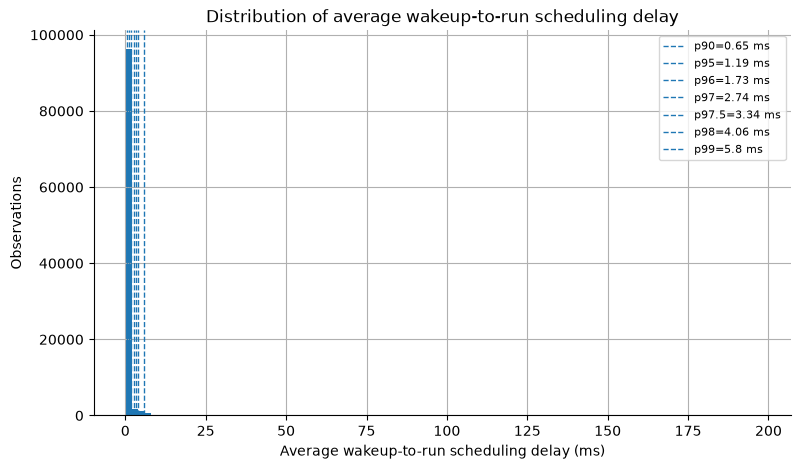

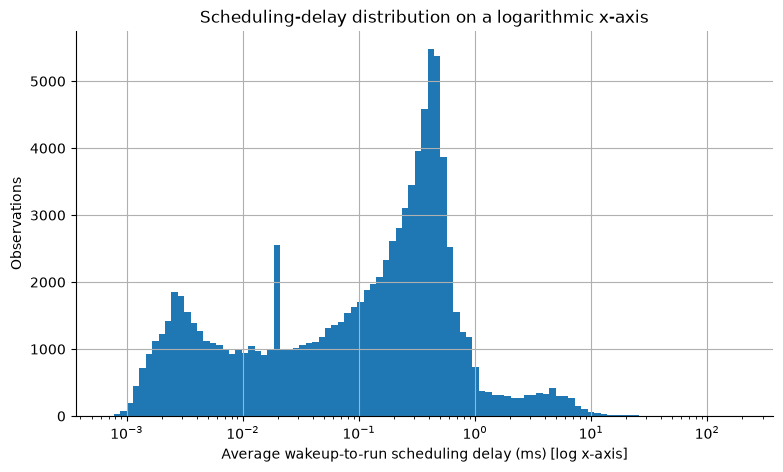

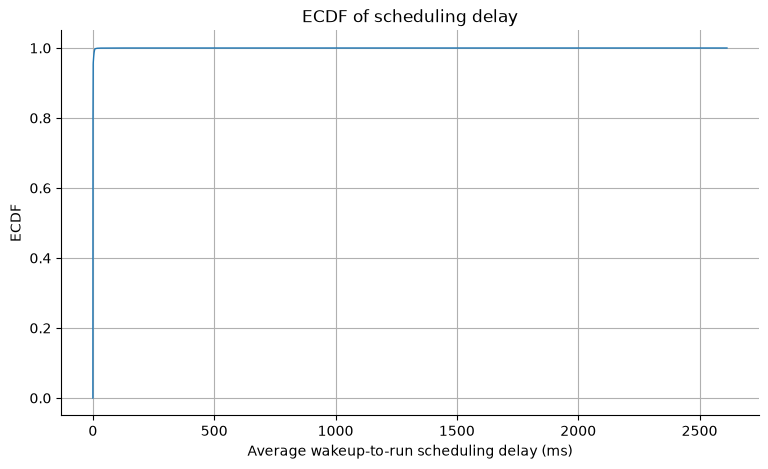

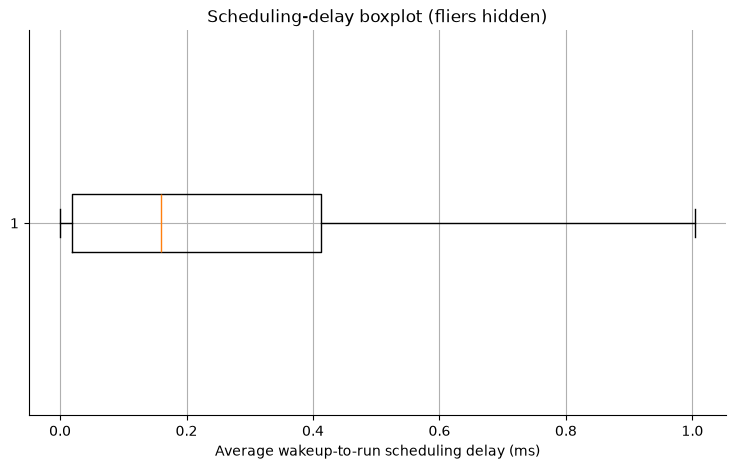

In [23]:
plot_s = analysis_df.sample(min(PLOT_SAMPLE_MAX, len(analysis_df)), random_state=RANDOM_STATE)

pvals = analysis_df["avg_stall_ms"].quantile(percentiles).to_dict()

fig, ax = plt.subplots()
ax.hist(plot_s["avg_stall_ms"], bins=100)
for p, v in pvals.items():
    ax.axvline(v, linestyle="--", linewidth=1, label=f"p{p*100:g}={v:.3g} ms")
ax.set_xlabel(STALL_LABEL)
ax.set_ylabel("Observations")
ax.set_title("Distribution of average wakeup-to-run scheduling delay")
ax.legend(fontsize=8)
plt.show()

fig, ax = plt.subplots()
positive = plot_s["avg_stall_ms"].clip(lower=np.finfo(float).tiny)
ax.hist(positive, bins=np.logspace(np.log10(positive.min()), np.log10(max(positive.max(), positive.min()*10)), 100))
ax.set_xscale("log")
ax.set_xlabel(STALL_LABEL + " [log x-axis]")
ax.set_ylabel("Observations")
ax.set_title("Scheduling-delay distribution on a logarithmic x-axis")
plt.show()

fig, ax = plt.subplots()
x = np.sort(analysis_df["avg_stall_ms"].to_numpy())
y = np.arange(1, len(x)+1)/len(x)
ax.plot(x, y, linewidth=1)
ax.set_xlabel(STALL_LABEL)
ax.set_ylabel("ECDF")
ax.set_title("ECDF of scheduling delay")
plt.show()

fig, ax = plt.subplots()
ax.boxplot(analysis_df["avg_stall_ms"], vert=False, showfliers=False)
ax.set_xlabel(STALL_LABEL)
ax.set_title("Scheduling-delay boxplot (fliers hidden)")
plt.show()

## 4. Independent resource metrics and grouping

In [10]:
# Resource-group definitions are based on the actual v7 feature names.
RESOURCE_GROUPS = {
    "CPU / scheduling pressure": [
        "ctx_switches", "cpu_migrations", "involuntary_switches",
        "voluntary_switches", "involuntary_ratio", "voluntary_ratio",
        "avg_runq_ratio", "runtime_per_switch",
    ],
    "Memory": [
        "minor_faults", "major_faults", "kmalloc_count", "kfree_count",
        "total_alloc_bytes", "alloc_pressure", "log_total_alloc_bytes",
    ],
    "I/O": [
        "read_count", "write_count", "read_bytes", "write_bytes",
        "read_write_ratio", "io_bytes_total", "log_io_bytes_total",
    ],
    "Lock contention": [
        "mutex_contentions", "avg_mutex_wait_ns",
        "rwsem_read_contentions", "rwsem_write_contentions", "lock_pressure",
    ],
    "System-call / scheduling activity": [
        "syscall_count", "avg_syscall_latency_ns",
        "log_avg_syscall_latency_ns", "log_max_syscall_latency_ns", "futex_count",
    ],
}

RESOURCE_GROUPS = {
    g: [c for c in cols if c in FEATURE_COLS]
    for g, cols in RESOURCE_GROUPS.items()
}
RESOURCE_GROUPS = {g: cols for g, cols in RESOURCE_GROUPS.items() if cols}

resource_features = [c for cols in RESOURCE_GROUPS.values() for c in cols]
resource_features = list(dict.fromkeys(resource_features))

print("Independent resource features by group:")
for group, cols in RESOURCE_GROUPS.items():
    print(f"\n{group} ({len(cols)}): {cols}")

Independent resource features by group:

CPU / scheduling pressure (8): ['ctx_switches', 'cpu_migrations', 'involuntary_switches', 'voluntary_switches', 'involuntary_ratio', 'voluntary_ratio', 'avg_runq_ratio', 'runtime_per_switch']

Memory (7): ['minor_faults', 'major_faults', 'kmalloc_count', 'kfree_count', 'total_alloc_bytes', 'alloc_pressure', 'log_total_alloc_bytes']

I/O (7): ['read_count', 'write_count', 'read_bytes', 'write_bytes', 'read_write_ratio', 'io_bytes_total', 'log_io_bytes_total']

Lock contention (5): ['mutex_contentions', 'avg_mutex_wait_ns', 'rwsem_read_contentions', 'rwsem_write_contentions', 'lock_pressure']

System-call / scheduling activity (5): ['syscall_count', 'avg_syscall_latency_ns', 'log_avg_syscall_latency_ns', 'log_max_syscall_latency_ns', 'futex_count']


## 5. Stall delay versus independent resource metrics

In [11]:
def safe_spearman(x, y):
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 3:
        return np.nan, np.nan, int(mask.sum())
    r, p = spearmanr(x[mask], y[mask])
    return r, p, int(mask.sum())

def safe_pearson(x, y):
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 3:
        return np.nan, np.nan, int(mask.sum())
    # Pearson is reported only when both variables have nonzero variance.
    if np.std(x[mask]) == 0 or np.std(y[mask]) == 0:
        return np.nan, np.nan, int(mask.sum())
    r, p = pearsonr(x[mask], y[mask])
    return r, p, int(mask.sum())

corr_rows = []
x = analysis_df["avg_stall_ms"].to_numpy(dtype=float)

for group, cols in RESOURCE_GROUPS.items():
    for col in cols:
        y = pd.to_numeric(analysis_df[col], errors="coerce").to_numpy(dtype=float)
        sr, sp, n = safe_spearman(x, y)
        pr, pp, _ = safe_pearson(x, y)
        corr_rows.append({
            "group": group,
            "metric": col,
            "spearman_rho": sr,
            "spearman_p": sp,
            "pearson_r": pr,
            "pearson_p": pp,
            "n": n,
            "abs_spearman": abs(sr) if np.isfinite(sr) else np.nan,
        })

correlations = pd.DataFrame(corr_rows).sort_values("abs_spearman", ascending=False)
display(correlations)

,group,metric,spearman_rho,spearman_p,pearson_r,pearson_p,n,abs_spearman
7,CPU / scheduling pressure,runtime_per_switch,0.27223,0,-0.0096562,3.5422e-15,664256,0.27223
0,CPU / scheduling pressure,ctx_switches,0.25772,0,-0.0039868,0.0011566,664256,0.25772
2,CPU / scheduling pressure,involuntary_switches,0.25748,0,0.00077548,0.52737,664256,0.25748
3,CPU / scheduling pressure,voluntary_switches,0.21285,0,-0.0050589,3.7374e-05,664256,0.21285
4,CPU / scheduling pressure,involuntary_ratio,0.11444,0,0.054075,0,664256,0.11444
5,CPU / scheduling pressure,voluntary_ratio,-0.11425,0,-0.05407,0,664256,0.11425
8,Memory,minor_faults,0.080773,0,0.021214,5.4014e-67,664256,0.080773
9,Memory,major_faults,0.064109,0,-0.00014785,0.90409,664256,0.064109
24,Lock contention,rwsem_read_contentions,0.058122,0,-0.00080505,0.51174,664256,0.058122
31,System-call / scheduling activity,futex_count,-0.052599,0,-0.001476,0.22899,664256,0.052599


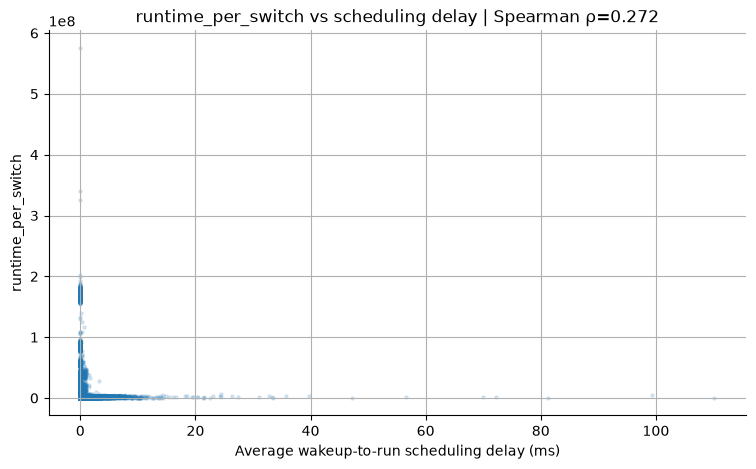

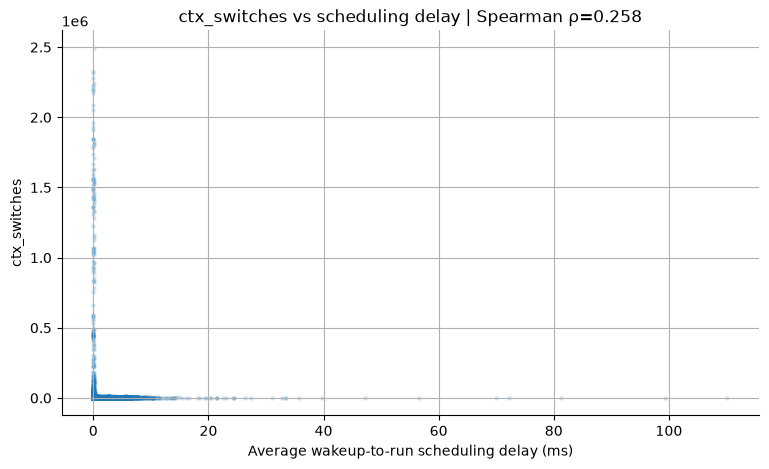

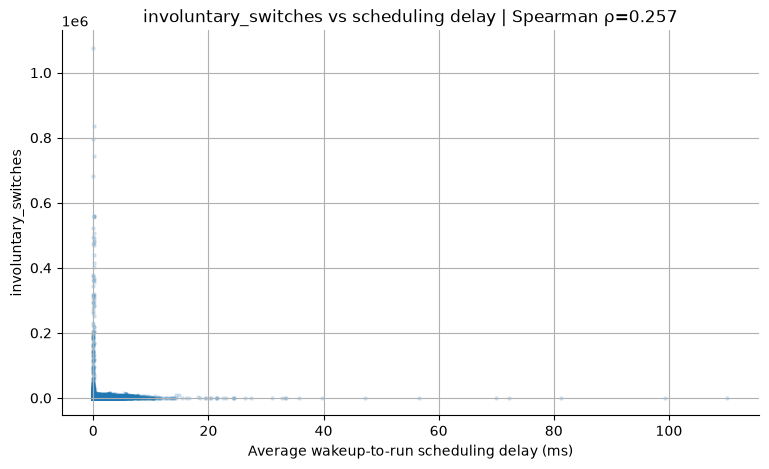

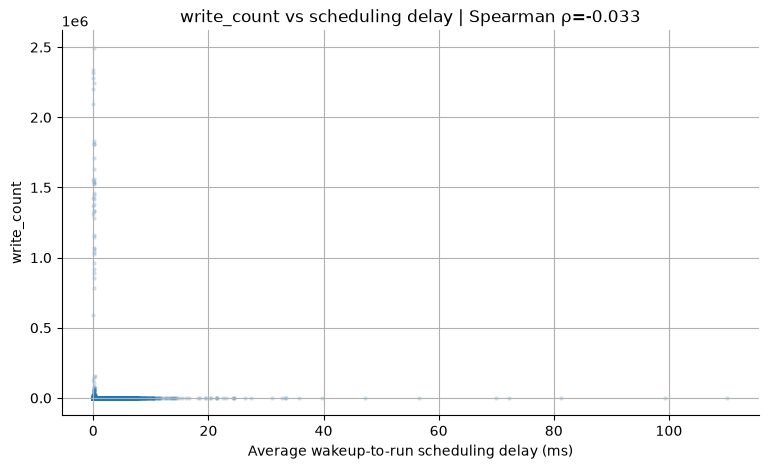

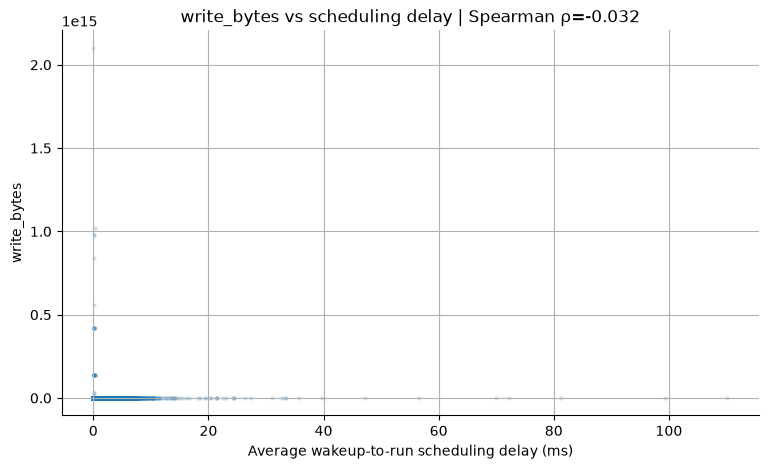

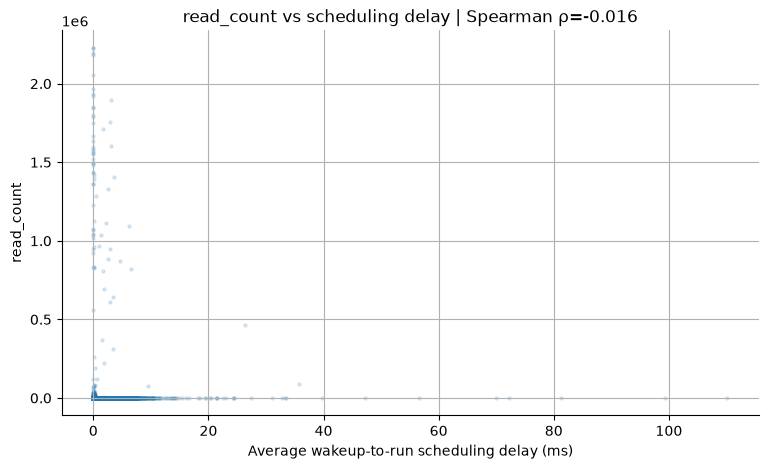

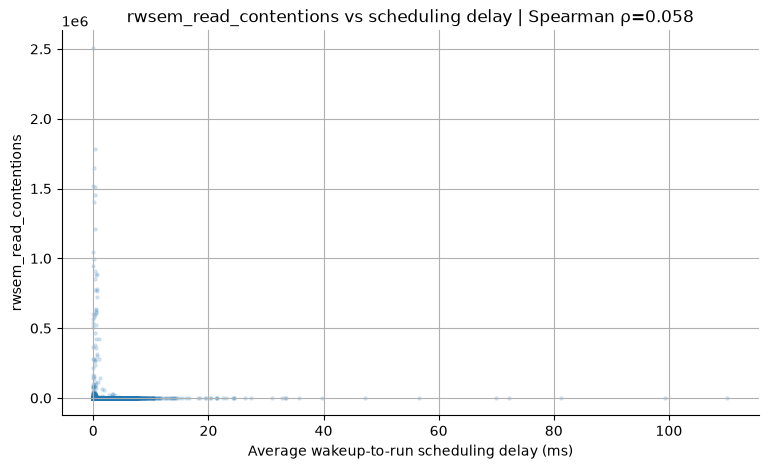

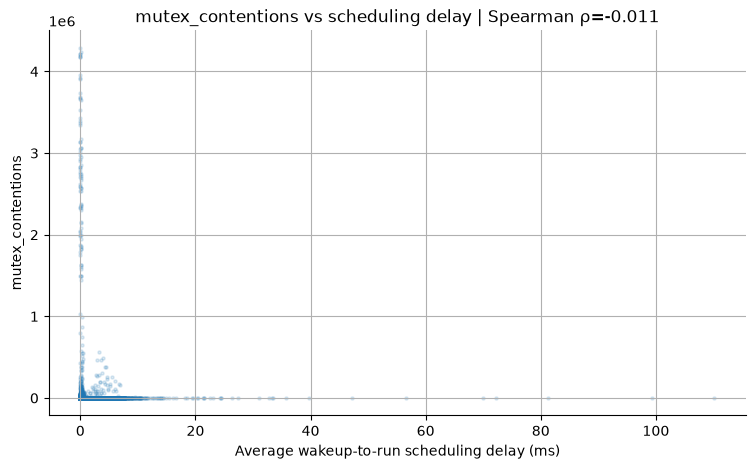

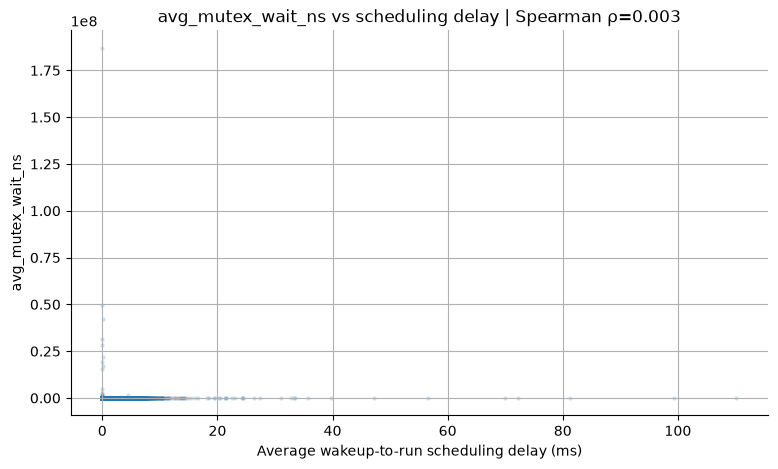

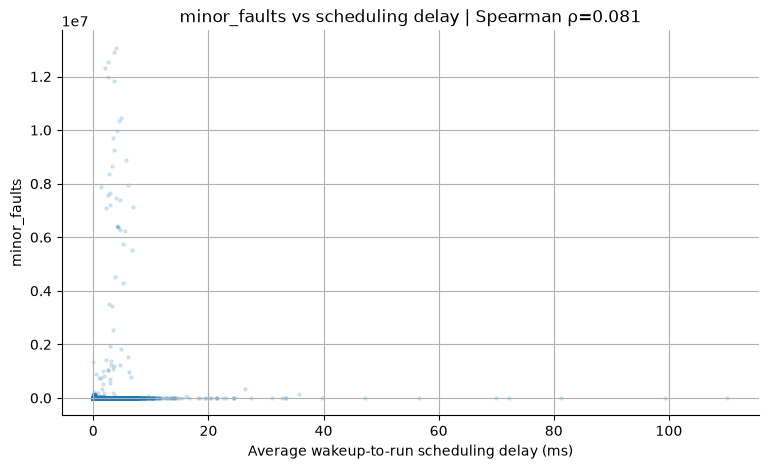

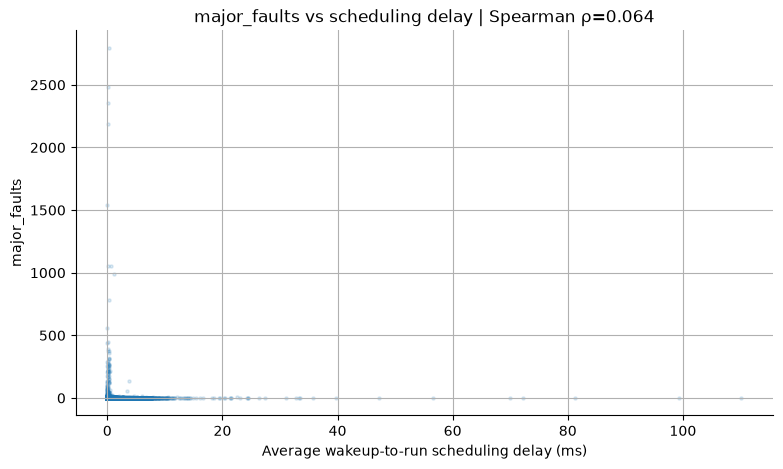

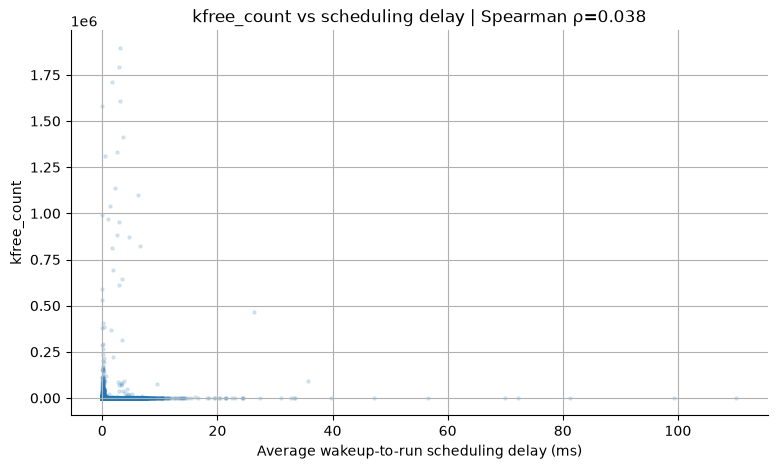

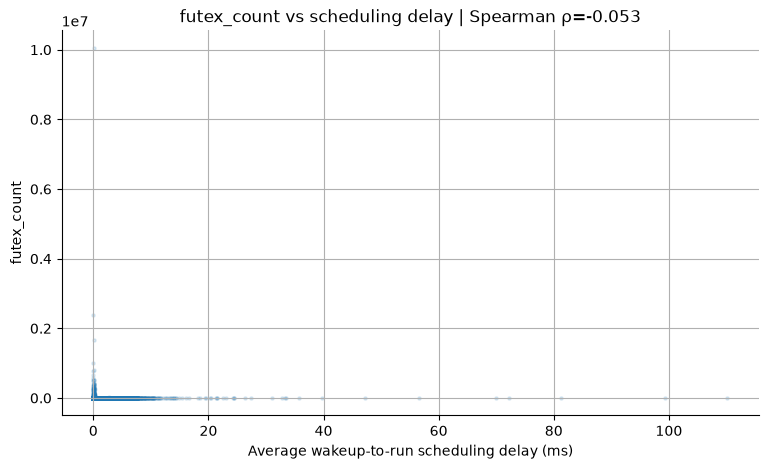

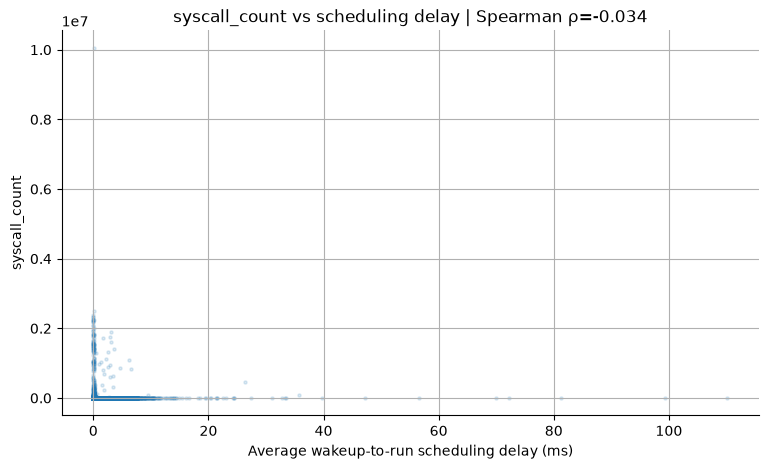

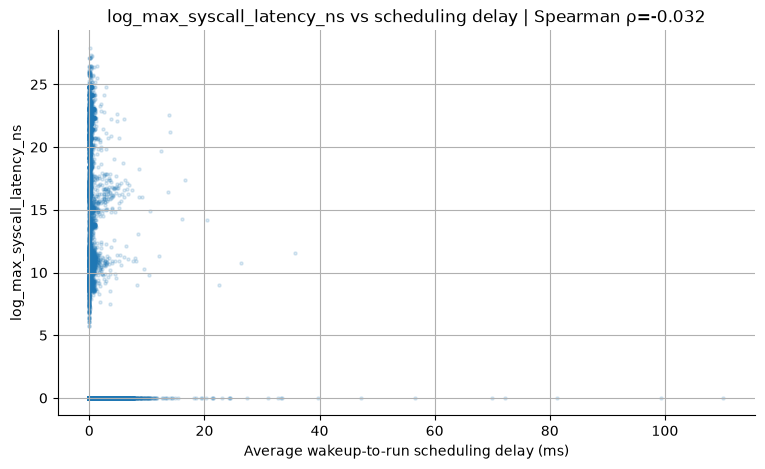

In [12]:
# Plot the strongest associations in each resource group.
top_per_group = (
    correlations.sort_values(["group", "abs_spearman"], ascending=[True, False])
    .groupby("group", as_index=False)
    .head(3)
)

for _, row in top_per_group.iterrows():
    col = row["metric"]
    y = pd.to_numeric(analysis_df[col], errors="coerce")
    mask = np.isfinite(x) & np.isfinite(y.to_numpy())
    if mask.sum() < 3:
        continue

    s = analysis_df.loc[mask, ["avg_stall_ms", col]].copy()
    if len(s) > 30_000:
        s = s.sample(30_000, random_state=RANDOM_STATE)

    fig, ax = plt.subplots()
    ax.scatter(s["avg_stall_ms"], s[col], s=5, alpha=0.15)
    ax.set_xlabel(STALL_LABEL)
    ax.set_ylabel(col)
    ax.set_title(f"{col} vs scheduling delay | Spearman ρ={row['spearman_rho']:.3f}")
    plt.show()

## 6. Ordered scheduling-delay bins

In [13]:
# Start with the requested bins and adapt the upper edge to the observed range.
requested_edges = np.array([0, .5, 1, 1.5, 2, 2.5, 3, 4, 5], dtype=float)
max_ms = analysis_df["avg_stall_ms"].max()

if max_ms <= 5:
    edges = requested_edges[requested_edges < max_ms]
    edges = np.unique(np.r_[edges, max_ms])
else:
    edges = np.unique(np.r_[requested_edges[requested_edges < max_ms], max_ms])

if len(edges) < 2:
    raise ValueError("Insufficient scheduling-delay range to construct bins.")

labels = []
for a, b in zip(edges[:-1], edges[1:]):
    labels.append(f"{a:g}–{b:g} ms")
if max_ms > 5:
    labels[-1] = f"{edges[-2]:g}–{edges[-1]:g} ms"

analysis_df["stall_bin"] = pd.cut(
    analysis_df["avg_stall_ms"],
    bins=edges,
    labels=labels,
    include_lowest=True,
    right=False,
)

# Ensure the final maximum value is represented.
analysis_df["stall_bin"] = analysis_df["stall_bin"].astype("object")
analysis_df.loc[
    analysis_df["avg_stall_ms"] == max_ms, "stall_bin"
] = labels[-1]

bin_rows = []
for b, g in analysis_df.groupby("stall_bin", observed=False, sort=False):
    if pd.isna(b):
        continue
    row = {
        "stall_bin": str(b),
        "n": len(g),
        "pct": 100 * len(g) / len(analysis_df),
    }
    for group, cols in RESOURCE_GROUPS.items():
        for col in cols:
            row[f"{col}__median"] = g[col].median()
    bin_rows.append(row)

bin_summary = pd.DataFrame(bin_rows)
display(bin_summary)

,stall_bin,n,pct,ctx_switches__median,cpu_migrations__median,involuntary_switches__median,voluntary_switches__median,involuntary_ratio__median,voluntary_ratio__median,avg_runq_ratio__median,runtime_per_switch__median,minor_faults__median,major_faults__median,kmalloc_count__median,kfree_count__median,total_alloc_bytes__median,alloc_pressure__median,log_total_alloc_bytes__median,read_count__median,write_count__median,read_bytes__median,write_bytes__median,read_write_ratio__median,io_bytes_total__median,log_io_bytes_total__median,mutex_contentions__median,avg_mutex_wait_ns__median,rwsem_read_contentions__median,rwsem_write_contentions__median,lock_pressure__median,syscall_count__median,avg_syscall_latency_ns__median,log_avg_syscall_latency_ns__median,log_max_syscall_latency_ns__median,futex_count__median
0,0–0.5 ms,553278,83.293,24,1,2,17,0.097656,0.90226,0,74321,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0.5–1 ms,73768,11.105,19,1,1,12,0.090909,0.90909,0,98664,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,1–1.5 ms,8406,1.2655,10,1,3,3,0.5,0.5,0,3.398e+05,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,1.5–2 ms,4493,0.6764,15,2,5,3,0.66667,0.33333,0,7.0557e+05,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,2.5–3 ms,3071,0.46232,235,15,180,3,0.91304,0.086957,0,2.1059e+06,1,0,0,7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,2–2.5 ms,2953,0.44456,35,4,16,4,0.8349,0.1651,0,1.1027e+06,4,0,0,8,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,4–5 ms,4572,0.68829,4629.5,234,4099.5,452,0.88253,0.11747,0,2.4346e+06,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,3–4 ms,4737,0.71313,4112,181,3598,90,0.90779,0.092212,0,2.4127e+06,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,5–2612.93 ms,8978,1.3516,3209,206,2841.5,247,0.88767,0.11233,0,2.3909e+06,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


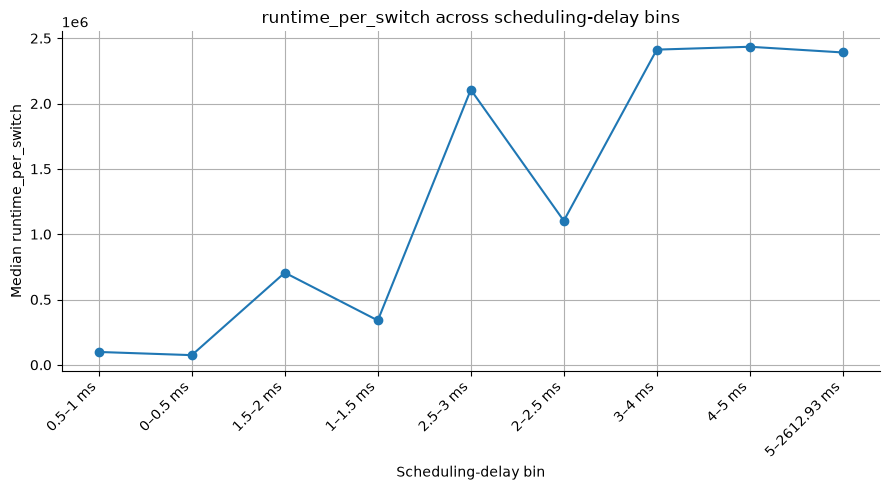

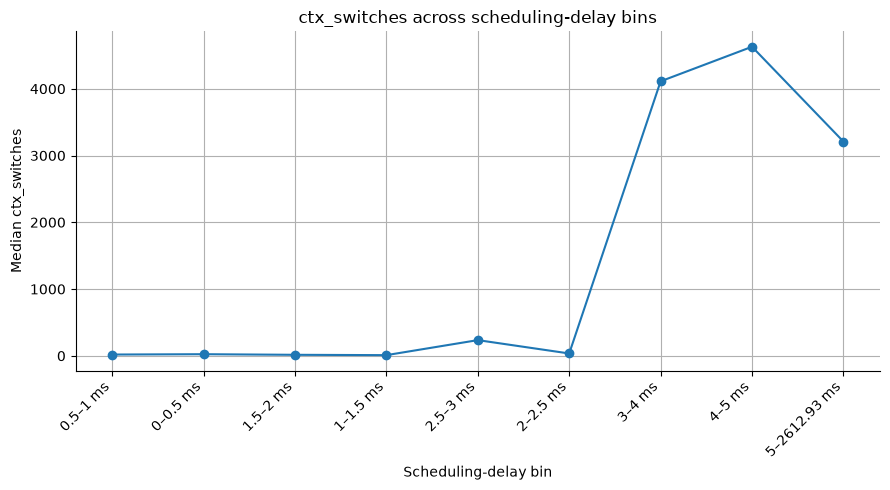

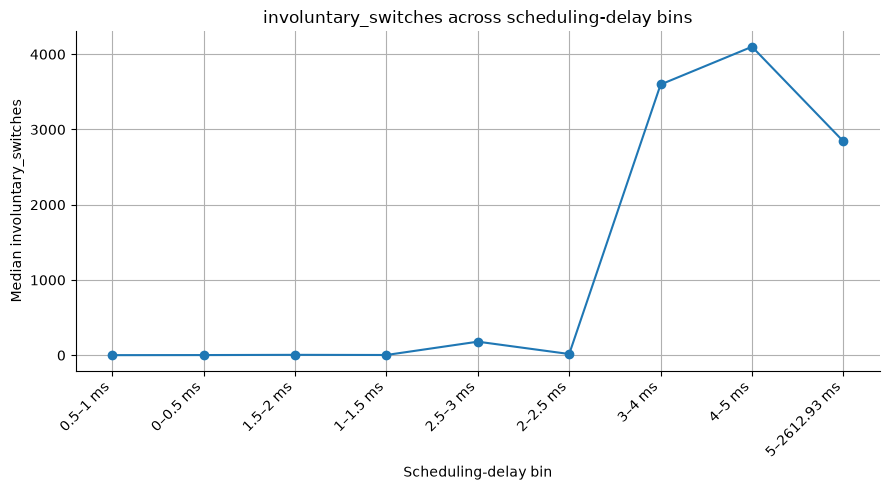

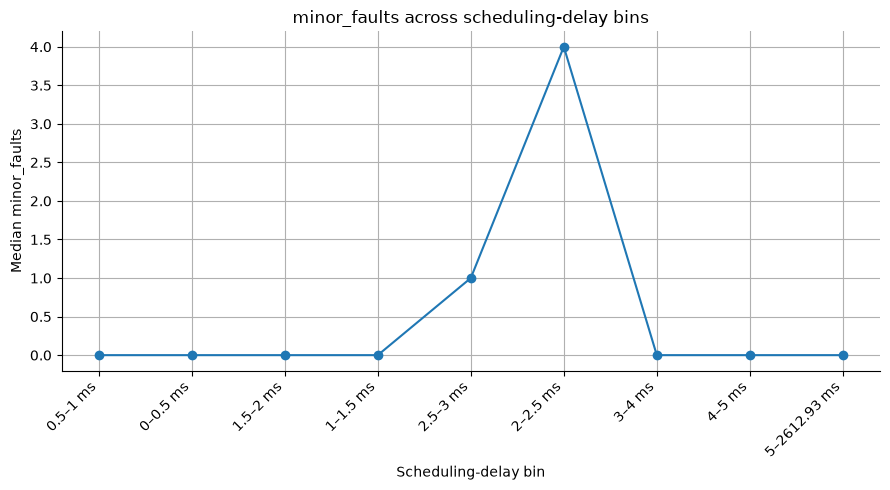

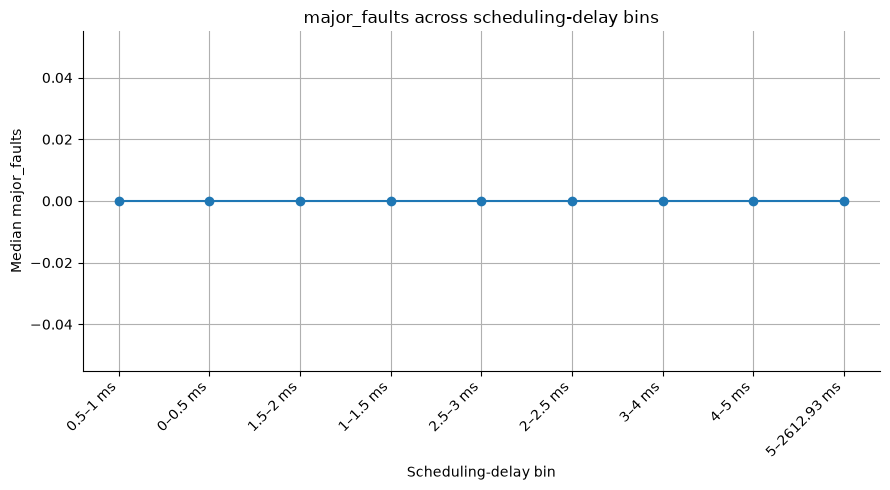

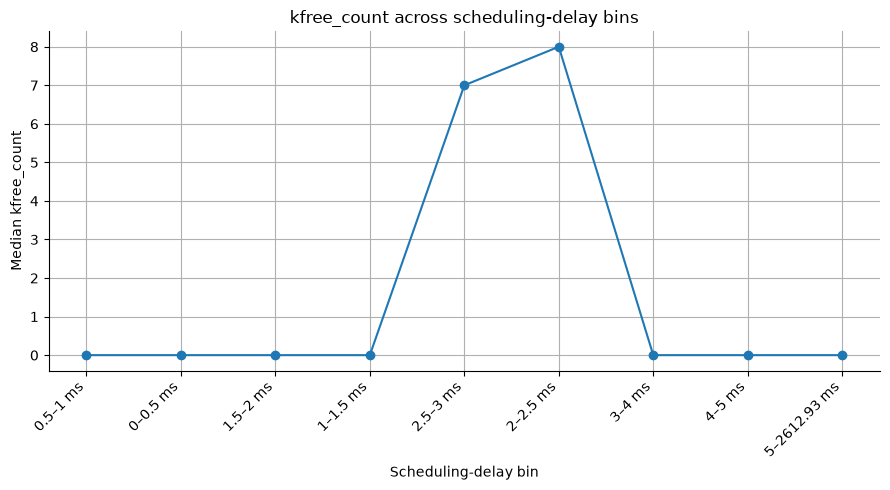

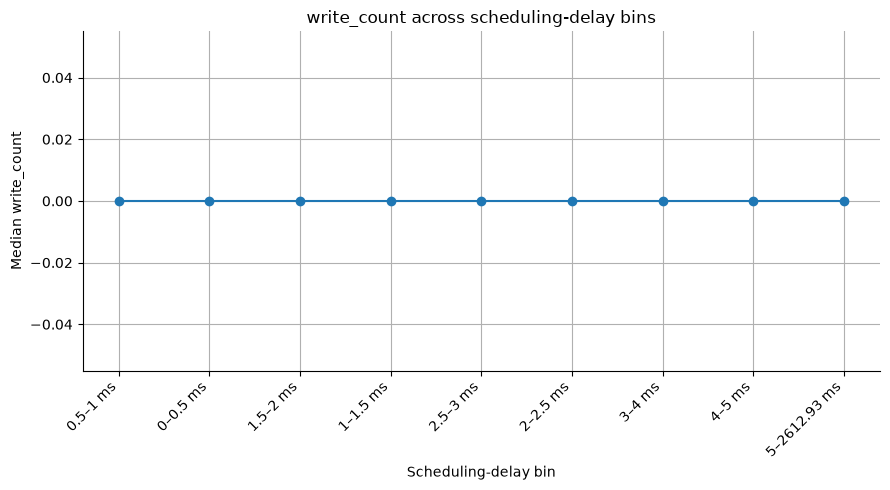

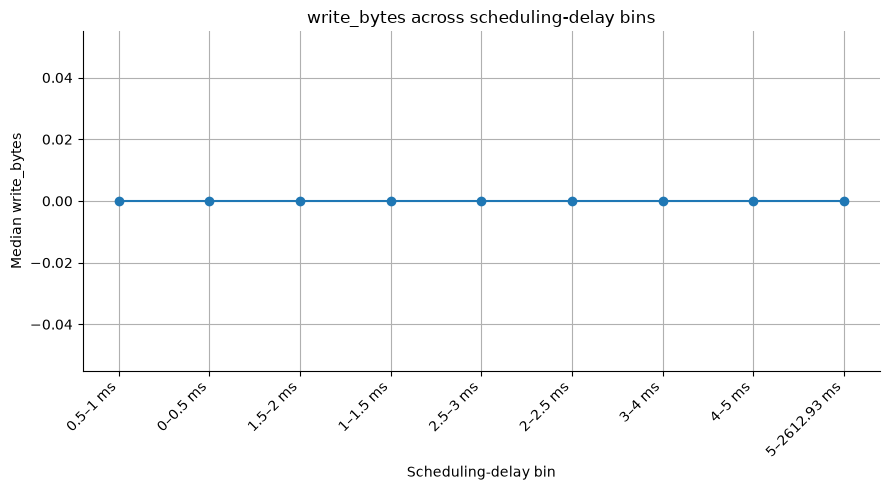

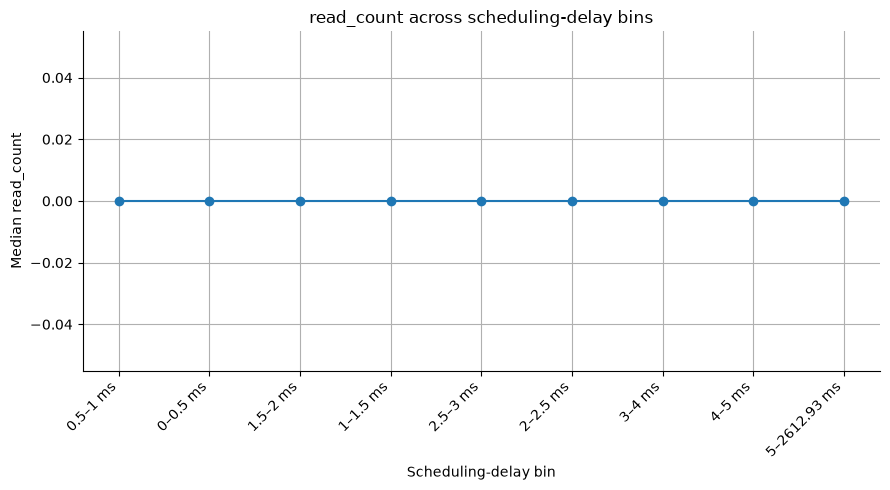

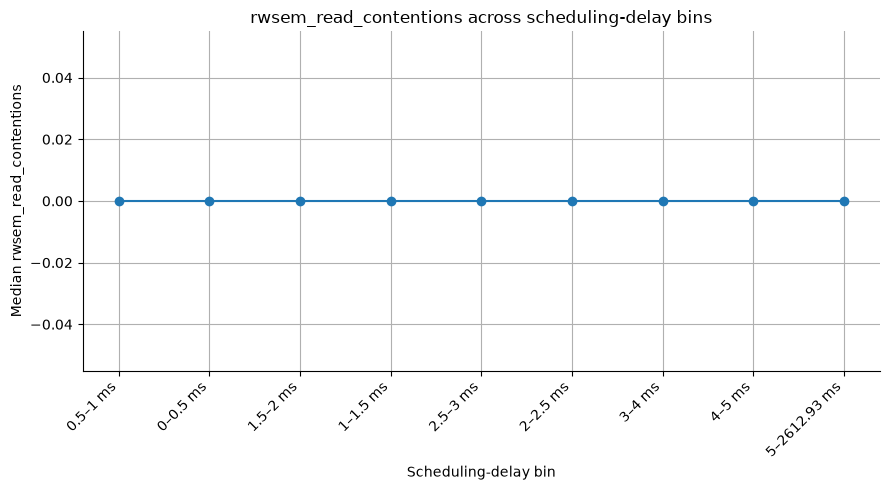

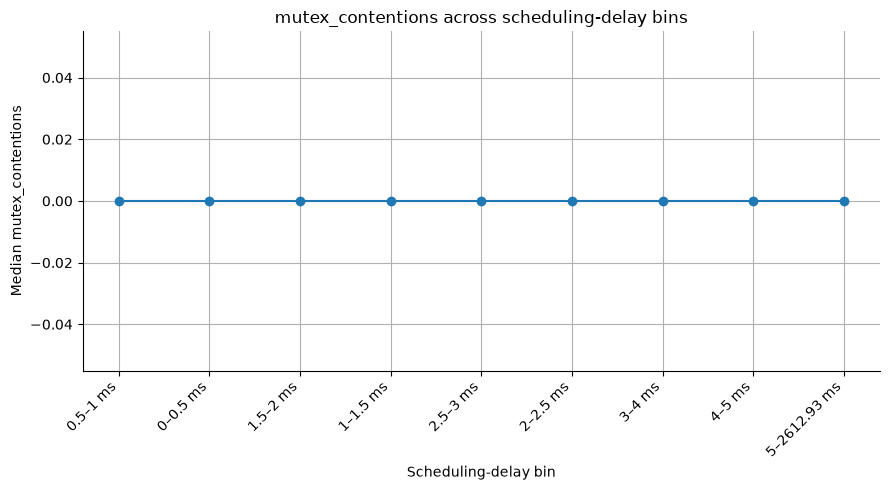

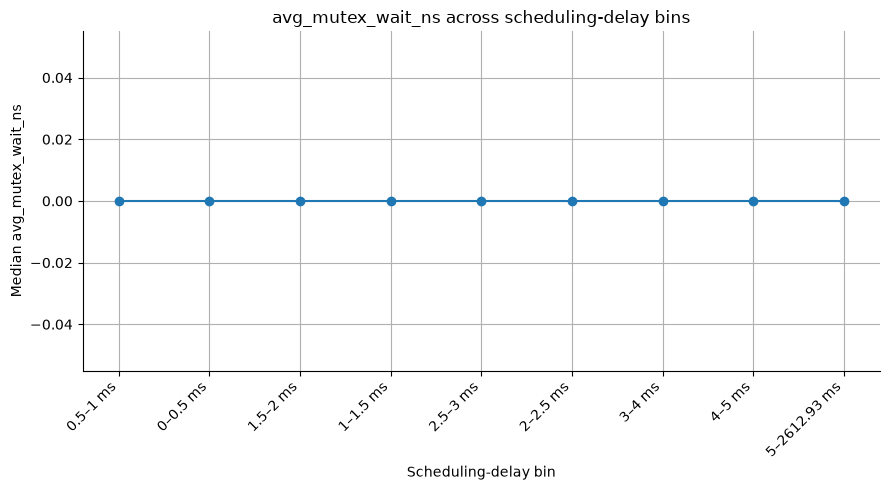

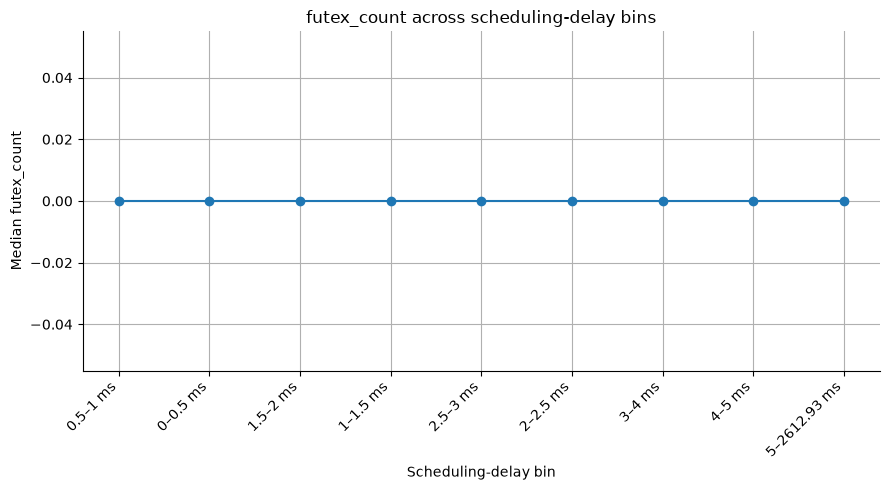

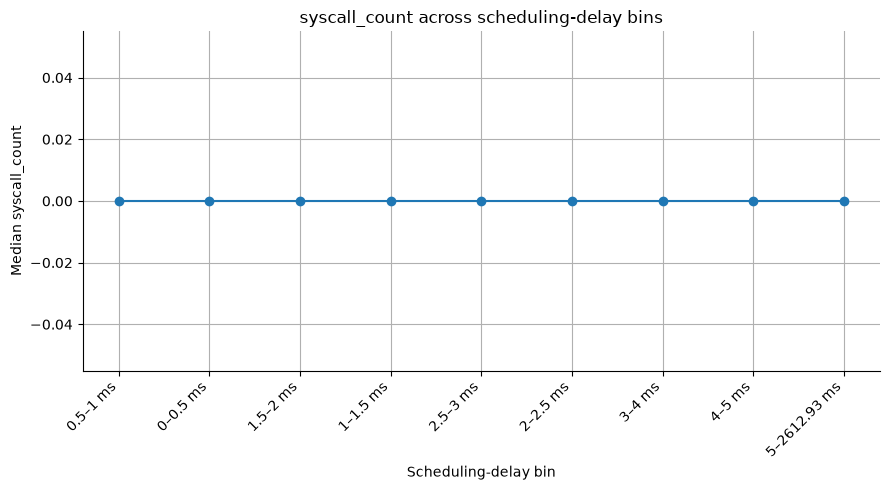

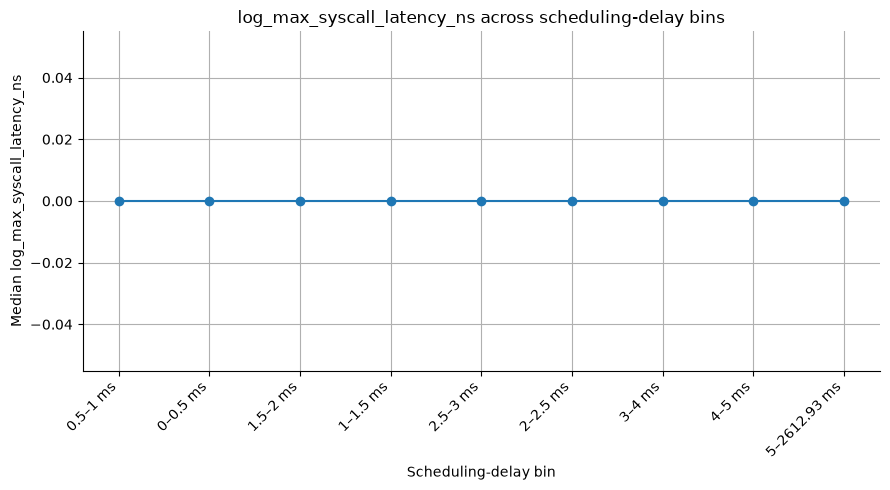

In [14]:
# Plot selected resource metrics across ordered delay bins.
for group, cols in RESOURCE_GROUPS.items():
    selected = (
        correlations[correlations["group"] == group]
        .sort_values("abs_spearman", ascending=False)
        .head(min(3, len(cols)))["metric"]
        .tolist()
    )
    for col in selected:
        med = analysis_df.groupby("stall_bin", observed=False)[col].median()
        fig, ax = plt.subplots()
        ax.plot(range(len(med)), med.values, marker="o")
        ax.set_xticks(range(len(med)))
        ax.set_xticklabels(med.index.astype(str), rotation=45, ha="right")
        ax.set_xlabel("Scheduling-delay bin")
        ax.set_ylabel(f"Median {col}")
        ax.set_title(f"{col} across scheduling-delay bins")
        plt.tight_layout()
        plt.show()

## 7. Dense threshold sweep

In [15]:
# Candidate thresholds span the observed meaningful range rather than hard-coding 0–5 ms.
# A linear grid is used for a dense exploratory sweep; percentile anchors are added explicitly.
lo = float(analysis_df["avg_stall_ms"].quantile(0.50))
hi = float(analysis_df["avg_stall_ms"].quantile(0.995))
thresholds = np.linspace(lo, hi, THRESHOLD_GRID_N)

anchor_thresholds = np.array([
    1.5,
    *percentile_table["threshold_ms"].to_numpy(dtype=float)
])
thresholds = np.unique(np.r_[thresholds, anchor_thresholds])
thresholds = thresholds[
    (thresholds > analysis_df["avg_stall_ms"].min()) &
    (thresholds < analysis_df["avg_stall_ms"].max())
]

print(f"Threshold candidates: {len(thresholds)}")
print(f"Range: {thresholds.min():.6g} to {thresholds.max():.6g} ms")

Threshold candidates: 108
Range: 0.159655 to 7.31213 ms


In [16]:
# Exact rank-biserial/Cliff-style effect size from global ranks.
# For a threshold T:
#   High = avg_stall_ms >= T
#   Low  = avg_stall_ms < T
# Positive values mean the resource metric tends to be larger in High than Low.
rank_cache = {}
for col in resource_features:
    s = pd.to_numeric(analysis_df[col], errors="coerce")
    rank_cache[col] = s.rank(method="average").to_numpy(dtype=float)

def rank_biserial_from_ranks(ranks, high_mask):
    valid = np.isfinite(ranks)
    h = high_mask & valid
    l = (~high_mask) & valid
    n1, n0 = h.sum(), l.sum()
    if n1 == 0 or n0 == 0:
        return np.nan
    sum_ranks_high = ranks[h].sum()
    u1 = sum_ranks_high - n1 * (n1 + 1) / 2
    return 2 * u1 / (n1 * n0) - 1

def threshold_effects(threshold, metrics=resource_features, include_medians=True):
    high_mask = analysis_df["avg_stall_ms"].to_numpy() >= threshold
    n_high = int(high_mask.sum())
    n_low = int((~high_mask).sum())

    row = {
        "threshold_ms": threshold,
        "high_count": n_high,
        "low_count": n_low,
        "high_pct": 100 * n_high / len(analysis_df),
    }

    for col in metrics:
        vals = pd.to_numeric(analysis_df[col], errors="coerce").to_numpy(dtype=float)
        valid = np.isfinite(vals)
        hvals = vals[high_mask & valid]
        lvals = vals[(~high_mask) & valid]

        row[f"{col}__effect"] = rank_biserial_from_ranks(rank_cache[col], high_mask)

        if include_medians:
            row[f"{col}__median_high"] = np.median(hvals) if len(hvals) else np.nan
            row[f"{col}__median_low"] = np.median(lvals) if len(lvals) else np.nan
            row[f"{col}__median_diff"] = (
                row[f"{col}__median_high"] - row[f"{col}__median_low"]
                if len(hvals) and len(lvals) else np.nan
            )
    return row

# The full resource-feature set is used. Exact rank-based effect sizes are efficient;
# medians are computed on the full valid data for each candidate threshold.
sweep_rows = []
for i, t in enumerate(thresholds, 1):
    sweep_rows.append(threshold_effects(float(t)))
    if i % 10 == 0 or i == len(thresholds):
        print(f"Completed {i}/{len(thresholds)} thresholds")

threshold_sweep = pd.DataFrame(sweep_rows)
display(threshold_sweep.head())

Completed 10/108 thresholds
Completed 20/108 thresholds
Completed 30/108 thresholds
Completed 40/108 thresholds
Completed 50/108 thresholds
Completed 60/108 thresholds
Completed 70/108 thresholds
Completed 80/108 thresholds
Completed 90/108 thresholds
Completed 100/108 thresholds
Completed 108/108 thresholds


,threshold_ms,high_count,low_count,high_pct,ctx_switches__effect,ctx_switches__median_high,ctx_switches__median_low,ctx_switches__median_diff,cpu_migrations__effect,cpu_migrations__median_high,cpu_migrations__median_low,cpu_migrations__median_diff,involuntary_switches__effect,involuntary_switches__median_high,involuntary_switches__median_low,involuntary_switches__median_diff,voluntary_switches__effect,voluntary_switches__median_high,voluntary_switches__median_low,voluntary_switches__median_diff,involuntary_ratio__effect,involuntary_ratio__median_high,involuntary_ratio__median_low,involuntary_ratio__median_diff,voluntary_ratio__effect,voluntary_ratio__median_high,voluntary_ratio__median_low,voluntary_ratio__median_diff,avg_runq_ratio__effect,avg_runq_ratio__median_high,avg_runq_ratio__median_low,avg_runq_ratio__median_diff,runtime_per_switch__effect,runtime_per_switch__median_high,runtime_per_switch__median_low,runtime_per_switch__median_diff,minor_faults__effect,minor_faults__median_high,minor_faults__median_low,minor_faults__median_diff,major_faults__effect,major_faults__median_high,major_faults__median_low,major_faults__median_diff,kmalloc_count__effect,kmalloc_count__median_high,kmalloc_count__median_low,kmalloc_count__median_diff,kfree_count__effect,kfree_count__median_high,...,read_write_ratio__median_low,read_write_ratio__median_diff,io_bytes_total__effect,io_bytes_total__median_high,io_bytes_total__median_low,io_bytes_total__median_diff,log_io_bytes_total__effect,log_io_bytes_total__median_high,log_io_bytes_total__median_low,log_io_bytes_total__median_diff,mutex_contentions__effect,mutex_contentions__median_high,mutex_contentions__median_low,mutex_contentions__median_diff,avg_mutex_wait_ns__effect,avg_mutex_wait_ns__median_high,avg_mutex_wait_ns__median_low,avg_mutex_wait_ns__median_diff,rwsem_read_contentions__effect,rwsem_read_contentions__median_high,rwsem_read_contentions__median_low,rwsem_read_contentions__median_diff,rwsem_write_contentions__effect,rwsem_write_contentions__median_high,rwsem_write_contentions__median_low,rwsem_write_contentions__median_diff,lock_pressure__effect,lock_pressure__median_high,lock_pressure__median_low,lock_pressure__median_diff,syscall_count__effect,syscall_count__median_high,syscall_count__median_low,syscall_count__median_diff,avg_syscall_latency_ns__effect,avg_syscall_latency_ns__median_high,avg_syscall_latency_ns__median_low,avg_syscall_latency_ns__median_diff,log_avg_syscall_latency_ns__effect,log_avg_syscall_latency_ns__median_high,log_avg_syscall_latency_ns__median_low,log_avg_syscall_latency_ns__median_diff,log_max_syscall_latency_ns__effect,log_max_syscall_latency_ns__median_high,log_max_syscall_latency_ns__median_low,log_max_syscall_latency_ns__median_diff,futex_count__effect,futex_count__median_high,futex_count__median_low,futex_count__median_diff
0,0.15965,332128,332128,50,0.23352,35,13,22,0.026076,1,1,0,0.21868,3,1,2,0.20728,25,9,16,0.074279,0.125,0.083333,0.041667,-0.074079,0.875,0.91667,-0.041667,0,0,0,0,0.27988,1.0505e+05,54797,50255,0.021874,0,0,0,0.017816,0,0,0,0.0030454,0,0,0,0.0089546,0,...,0,0,-0.015844,0,0,0,-0.015844,0,0,0,-0.01901,0,0,0,-0.010749,0,0,0,0.022797,0,0,0,0,0,0,0,-0.012943,0,0,0,-0.038094,0,0,0,-0.036076,0,0,0,-0.036076,0,0,0,-0.036884,0,0,0,-0.025781,0,0,0
1,0.2319,282663,381593,42.553,0.18647,34,16,18,-0.036613,1,1,0,0.17266,3,1,2,0.15743,24,11,13,0.062857,0.11765,0.1,0.017647,-0.062684,0.88235,0.9,-0.017647,0,0,0,0,0.28208,1.0819e+05,58722,49464,0.026149,0,0,0,0.020613,0,0,0,-0.004027,0,0,0,0.0034279,0,...,0,0,-0.014962,0,0,0,-0.014962,0,0,0,-0.024928,0,0,0,-0.016627,0,0,0,0.020653,0,0,0,0,0,0,0,-0.017109,0,0,0,-0.037899,0,0,0,-0.035864,0,0,0,-0.035864,0,0,0,-0.036777,0,0,0,-0.029621,0,0,0
2,0.30415,236594,427662,35.618,0.15437,34,18,16,-0.082874,1,1,0,0.13964,2,1,1,0.12679,24,12,12,0.054934,0.11111,0.10949,0.0016221,-0.054772,0.88889,0.89041,-0.0015221,0,0,0,0,0.28026,1.1039e+05,62683,47710,0.03864,0,0,0,0.026732,0,0,0,-0.0058376,0,0,0,0.0039993,0

## 8. Effect size versus threshold

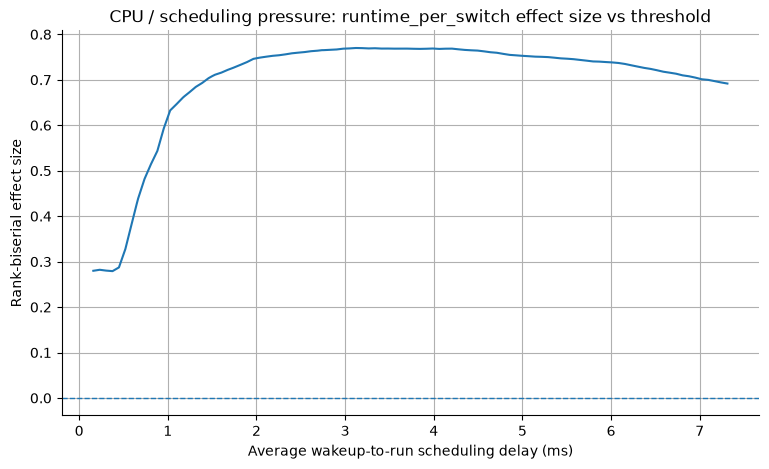

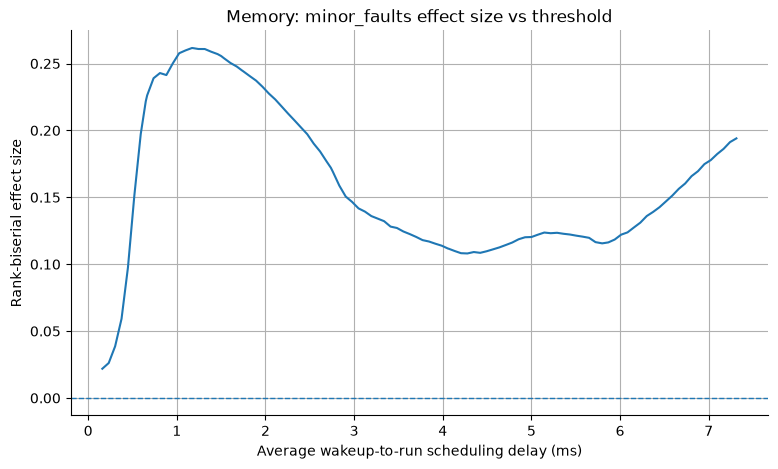

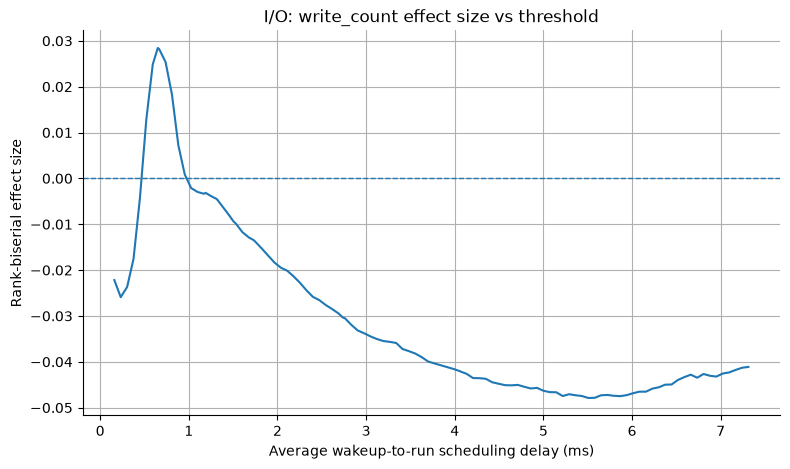

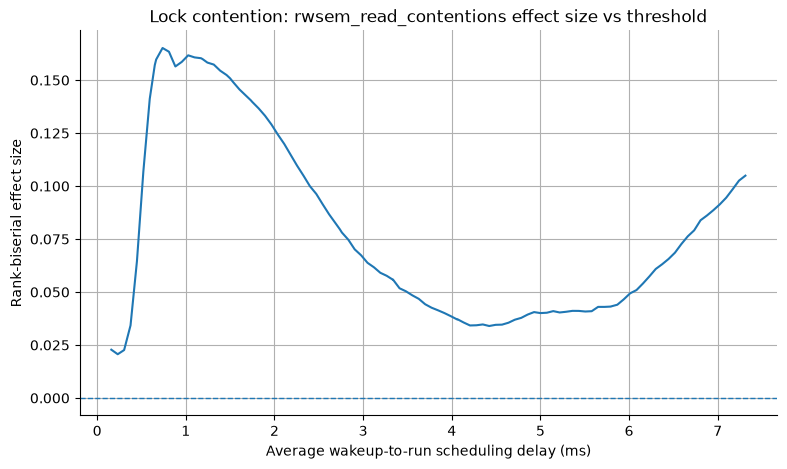

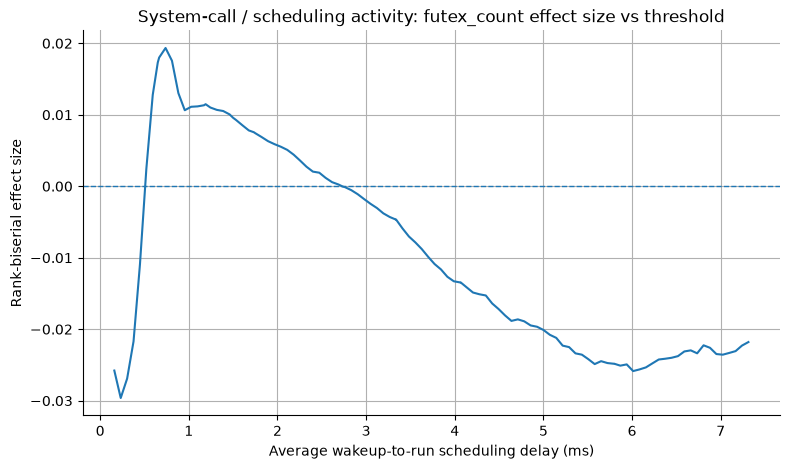

In [17]:
# Plot the strongest metric in each resource group over the threshold sweep.
effect_plot_metrics = {}
for group, cols in RESOURCE_GROUPS.items():
    best_col = (
        correlations[correlations["group"] == group]
        .sort_values("abs_spearman", ascending=False)
        .iloc[0]["metric"]
    )
    effect_plot_metrics[group] = best_col

for group, col in effect_plot_metrics.items():
    fig, ax = plt.subplots()
    ax.plot(
        threshold_sweep["threshold_ms"],
        threshold_sweep[f"{col}__effect"],
        linewidth=1.5,
    )
    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_xlabel(STALL_LABEL)
    ax.set_ylabel("Rank-biserial effect size")
    ax.set_title(f"{group}: {col} effect size vs threshold")
    plt.show()

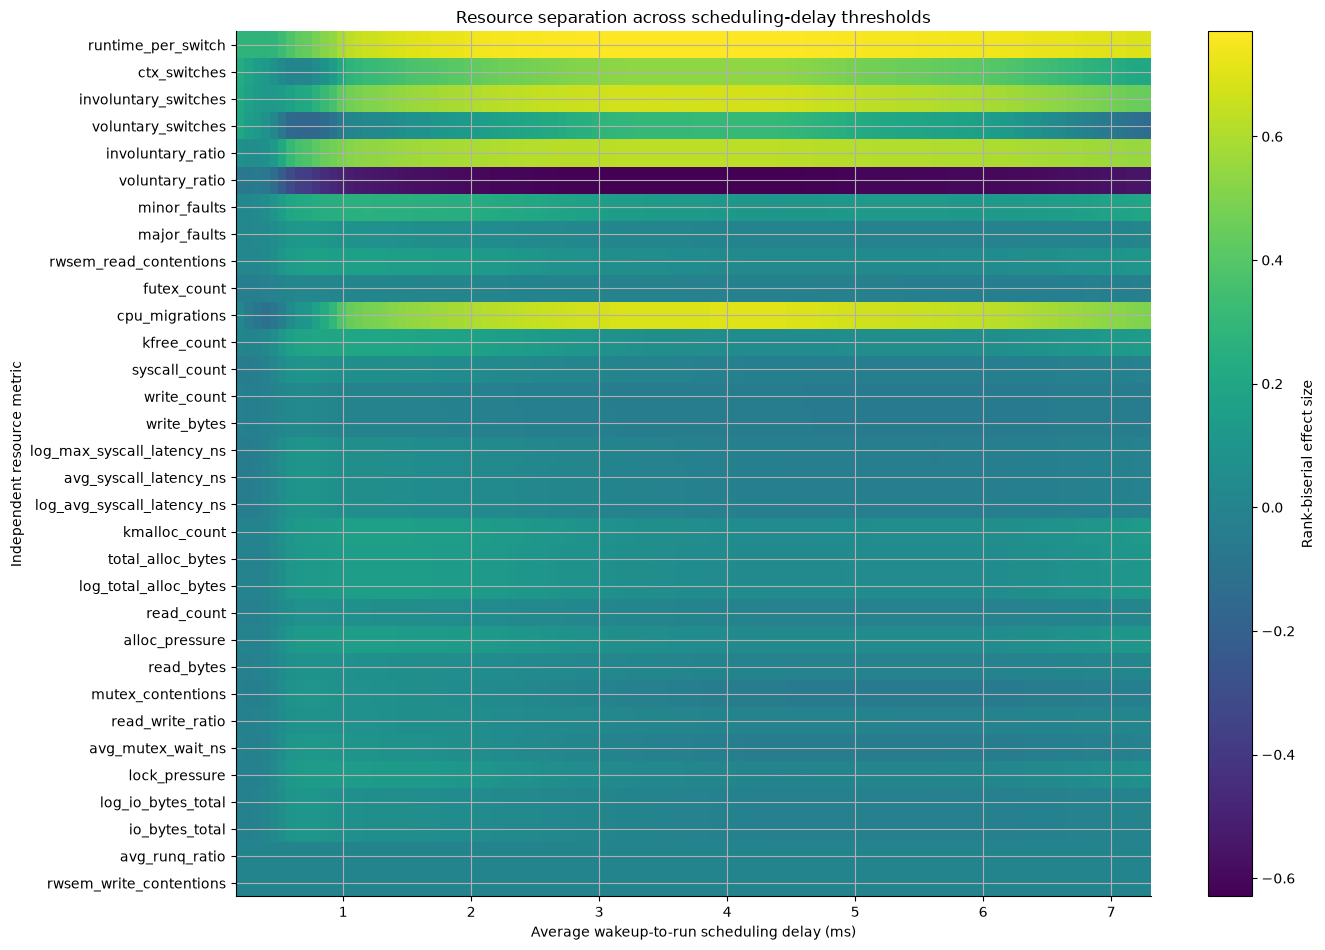

In [18]:
# Heatmap: rows = important resource metrics; columns = candidate thresholds.
heat_metrics = correlations.sort_values("abs_spearman", ascending=False)["metric"].drop_duplicates().tolist()

heat = np.array([
    threshold_sweep[f"{m}__effect"].to_numpy()
    for m in heat_metrics
])

fig, ax = plt.subplots(figsize=(14, max(6, len(heat_metrics)*0.3)))
im = ax.imshow(
    heat,
    aspect="auto",
    interpolation="nearest",
    extent=[
        threshold_sweep["threshold_ms"].min(),
        threshold_sweep["threshold_ms"].max(),
        len(heat_metrics)-0.5,
        -0.5,
    ],
)
ax.set_yticks(range(len(heat_metrics)))
ax.set_yticklabels(heat_metrics)
ax.set_xlabel(STALL_LABEL)
ax.set_ylabel("Independent resource metric")
ax.set_title("Resource separation across scheduling-delay thresholds")
fig.colorbar(im, ax=ax, label="Rank-biserial effect size")
plt.tight_layout()
plt.show()

## 9. Selected threshold comparisons

In [19]:
selected_thresholds = {
    "1.5 ms": 1.5,
    "p95": float(percentile_table.loc["p95", "threshold_ms"]),
    "p96": float(percentile_table.loc["p96", "threshold_ms"]),
    "p97": float(percentile_table.loc["p97", "threshold_ms"]),
    "p97.5": float(percentile_table.loc["p97.5", "threshold_ms"]),
    "p98": float(percentile_table.loc["p98", "threshold_ms"]),
}

def nearest_sweep_row(t):
    idx = np.abs(threshold_sweep["threshold_ms"].to_numpy() - t).argmin()
    return threshold_sweep.iloc[idx]

summary_rows = []
for basis, t in selected_thresholds.items():
    row = nearest_sweep_row(t)
    summary = {
        "Threshold basis": basis,
        "Threshold ms": t,
        "High %": row["high_pct"],
    }
    for group, cols in RESOURCE_GROUPS.items():
        best = (
            correlations[correlations["group"] == group]
            .sort_values("abs_spearman", ascending=False)
            .iloc[0]["metric"]
        )
        summary[f"{group} effect"] = row[f"{best}__effect"]
    # Distribution separation is represented by the median absolute rank-biserial effect
    # across all independent metrics, not by a model score.
    effects = [
        row[f"{m}__effect"] for m in resource_features
        if np.isfinite(row[f"{m}__effect"])
    ]
    summary["Median |effect| across metrics"] = np.median(np.abs(effects)) if effects else np.nan
    summary_rows.append(summary)

threshold_summary = pd.DataFrame(summary_rows)
display(threshold_summary)

,Threshold basis,Threshold ms,High %,CPU / scheduling pressure effect,Memory effect,I/O effect,Lock contention effect,System-call / scheduling activity effect,Median |effect| across metrics
0,1.5 ms,1.5,4.3363,0.70801,0.25559,-0.0092897,0.15083,0.0095725,0.074076
1,p95,1.1893,5,0.6641,0.26144,-0.0031553,0.15993,0.011479,0.077968
2,p96,1.7336,4.0001,0.72609,0.24489,-0.013494,0.14047,0.0075563,0.064439
3,p97,2.7377,3,0.76519,0.17207,-0.030358,0.079601,-4.9398e-05,0.029928
4,p97.5,3.3381,2.5001,0.76944,0.13215,-0.035887,0.055761,-0.0046753,0.028856
5,p98,4.0648,2.0001,0.76798,0.11161,-0.042118,0.037151,-0.013434,0.038106


In [20]:
# High/Low distribution comparisons at selected thresholds.
# P-values are reported with a dependence warning; effect sizes and practical median
# differences remain the primary evidence.
distribution_rows = []

important_metrics = (
    correlations.sort_values("abs_spearman", ascending=False)
    .groupby("group", as_index=False)
    .head(2)["metric"]
    .tolist()
)

for basis, t in selected_thresholds.items():
    high = analysis_df["avg_stall_ms"] >= t
    for metric in important_metrics:
        vals = pd.to_numeric(analysis_df[metric], errors="coerce")
        h = vals[high].dropna().to_numpy()
        l = vals[~high].dropna().to_numpy()
        if len(h) == 0 or len(l) == 0:
            continue
        mw = mannwhitneyu(h, l, alternative="two-sided")
        ks = ks_2samp(h, l)
        rb = rank_biserial_from_ranks(rank_cache[metric], high.to_numpy())
        distribution_rows.append({
            "threshold_basis": basis,
            "threshold_ms": t,
            "metric": metric,
            "n_high": len(h),
            "n_low": len(l),
            "median_high": np.median(h),
            "median_low": np.median(l),
            "median_difference": np.median(h)-np.median(l),
            "rank_biserial": rb,
            "mann_whitney_p": mw.pvalue,
            "KS_statistic": ks.statistic,
            "KS_p": ks.pvalue,
        })

distribution_comparison = pd.DataFrame(distribution_rows)
display(distribution_comparison.sort_values(["threshold_basis", "metric"]))

,threshold_basis,threshold_ms,metric,n_high,n_low,median_high,median_low,median_difference,rank_biserial,mann_whitney_p,KS_statistic,KS_p
1,1.5 ms,1.5,ctx_switches,28804,635452,2048.5,23,2025.5,0.37698,0,0.46654,0
5,1.5 ms,1.5,futex_count,28804,635452,0,0,0,0.0095725,9.7767e-13,0.011187,0.0020056
3,1.5 ms,1.5,major_faults,28804,635452,0,0,0,0.068915,0,0.070999,3.146e-121
2,1.5 ms,1.5,minor_faults,28804,635452,0,0,0,0.25559,0,0.26035,0
9,1.5 ms,1.5,mutex_contentions,28804,635452,0,0,0,0.063284,9.5486e-178,0.066034,6.5514e-105
0,1.5 ms,1.5,runtime_per_switch,28804,635452,2.3548e+06,78241,2.2765e+06,0.70801,0,0.66879,0
4,1.5 ms,1.5,rwsem_read_contentions,28804,635452,0,0,0,0.15083,0,0.14723,0
6,1.5 ms,1.5,syscall_count,28804,635452,0,0,0,0.05624,1.0843e-175,0.056577,4.1615e-77
8,1.5 ms,1.5,write_bytes,28804,635452,0,0,0,-0.0081764,1.148e-07,0.011054,0.0023621
7,1.5 ms,1.5,write_count,28804,635452,0,0,0,-0.0092897,1.7335e-09,0.021794,8.4177e-12


TypeError: Axes.boxplot() got an unexpected keyword argument 'labels'. Did you mean 'label'?

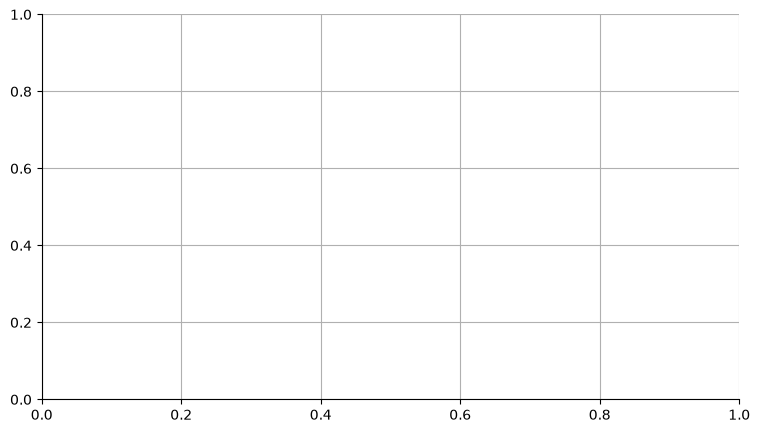

In [21]:
# Visual comparison for the selected thresholds.
for basis, t in selected_thresholds.items():
    high = analysis_df["avg_stall_ms"] >= t
    for metric in important_metrics[:8]:
        vals = pd.to_numeric(analysis_df[metric], errors="coerce")
        h = vals[high].dropna()
        l = vals[~high].dropna()
        if len(h) < 2 or len(l) < 2:
            continue

        # Plot sampled distributions to keep rendering manageable.
        hs = h.sample(min(20_000, len(h)), random_state=RANDOM_STATE)
        ls = l.sample(min(20_000, len(l)), random_state=RANDOM_STATE)

        fig, ax = plt.subplots()
        ax.boxplot([ls, hs], labels=["Low", "High"], showfliers=False)
        ax.set_ylabel(metric)
        ax.set_title(f"{metric}: Low vs High at {basis} ({t:.4g} ms)")
        plt.show()

## 10. ECDF comparisons for candidate thresholds

In [ ]:
for basis, t in selected_thresholds.items():
    high = analysis_df["avg_stall_ms"] >= t
    for metric in important_metrics[:6]:
        vals = pd.to_numeric(analysis_df[metric], errors="coerce")
        h = vals[high].dropna()
        l = vals[~high].dropna()
        if len(h) < 2 or len(l) < 2:
            continue

        hs = h.sample(min(30_000, len(h)), random_state=RANDOM_STATE)
        ls = l.sample(min(30_000, len(l)), random_state=RANDOM_STATE)

        fig, ax = plt.subplots()
        for arr, label in [(ls, "Low"), (hs, "High")]:
            xx = np.sort(arr.to_numpy())
            yy = np.arange(1, len(xx)+1) / len(xx)
            ax.plot(xx, yy, linewidth=1.2, label=label)
        ax.set_xlabel(metric)
        ax.set_ylabel("ECDF")
        ax.set_title(f"{metric}: ECDF at {basis} ({t:.4g} ms)")
        ax.legend()
        plt.show()

## 11. Change-point / segmented relationship analysis

In [ ]:
# Candidate change points are estimated independently for the strongest resource metrics.
# The search compares a simple linear model with a continuous piecewise-linear model:
# y = a + b*x + c*max(x-break, 0).
#
# A breakpoint is retained only when the piecewise model materially improves BIC.
def fit_linear_piecewise(x, y, min_side=200):
    mask = np.isfinite(x) & np.isfinite(y)
    x = np.asarray(x[mask], dtype=float)
    y = np.asarray(y[mask], dtype=float)
    if len(x) < 2*min_side + 20:
        return None

    order = np.argsort(x)
    x, y = x[order], y[order]

    # Use quantile-spaced candidate breakpoints to avoid spending time at nearly empty tails.
    candidates = np.unique(np.quantile(x, np.linspace(.10, .90, 81)))
    candidates = candidates[(candidates > x[min_side]) & (candidates < x[-min_side-1])]
    if len(candidates) == 0:
        return None

    def bic(rss, n, k):
        rss = max(float(rss), np.finfo(float).tiny)
        return n*np.log(rss/n) + k*np.log(n)

    X0 = np.column_stack([np.ones(len(x)), x])
    beta0, *_ = np.linalg.lstsq(X0, y, rcond=None)
    resid0 = y - X0 @ beta0
    bic0 = bic(np.sum(resid0**2), len(y), 2)

    best = None
    for br in candidates:
        X1 = np.column_stack([np.ones(len(x)), x, np.maximum(x-br, 0)])
        beta1, *_ = np.linalg.lstsq(X1, y, rcond=None)
        resid1 = y - X1 @ beta1
        bic1 = bic(np.sum(resid1**2), len(y), 3)
        improvement = bic0 - bic1
        if best is None or bic1 < best["piecewise_bic"]:
            best = {
                "breakpoint_ms": br,
                "linear_bic": bic0,
                "piecewise_bic": bic1,
                "bic_improvement": improvement,
                "linear_beta": beta0,
                "piecewise_beta": beta1,
                "x": x,
                "y": y,
            }
    return best

# Use the top two metrics from each major resource group.
change_metrics = (
    correlations[correlations["group"].isin([
        "CPU / scheduling pressure", "Memory", "I/O", "Lock contention"
    ])]
    .sort_values("abs_spearman", ascending=False)
    .groupby("group", as_index=False)
    .head(2)["metric"]
    .tolist()
)

change_results = []
change_models = {}

x = analysis_df["avg_stall_ms"].to_numpy(dtype=float)
for metric in change_metrics:
    y = pd.to_numeric(analysis_df[metric], errors="coerce").to_numpy(dtype=float)
    result = fit_linear_piecewise(x, y)
    if result is not None:
        change_results.append({
            "metric": metric,
            "candidate_breakpoint_ms": result["breakpoint_ms"],
            "linear_BIC": result["linear_bic"],
            "piecewise_BIC": result["piecewise_bic"],
            "BIC_improvement": result["bic_improvement"],
        })
        change_models[metric] = result

change_points = pd.DataFrame(change_results).sort_values("BIC_improvement", ascending=False)
display(change_points)

In [ ]:
# Visualize the strongest candidate breakpoint(s).
for metric in change_points.head(6)["metric"]:
    result = change_models[metric]
    xx = result["x"]
    yy = result["y"]
    br = result["breakpoint_ms"]
    beta = result["piecewise_beta"]

    grid = np.linspace(np.nanpercentile(xx, 1), np.nanpercentile(xx, 99), 300)
    pred = beta[0] + beta[1]*grid + beta[2]*np.maximum(grid-br, 0)

    fig, ax = plt.subplots()
    sample_idx = rng.choice(len(xx), size=min(40_000, len(xx)), replace=False)
    ax.scatter(xx[sample_idx], yy[sample_idx], s=4, alpha=.12)
    ax.plot(grid, pred, linewidth=2)
    ax.axvline(br, linestyle="--", linewidth=1, label=f"candidate break = {br:.4g} ms")
    ax.set_xlabel(STALL_LABEL)
    ax.set_ylabel(metric)
    ax.set_title(f"Segmented relationship: {metric}")
    ax.legend()
    plt.show()

## 12. Multivariate anomaly analysis

In [ ]:
# Anomaly features are independent resource features only.
# avg_stall_ns / avg_stall_ms and all target-derived fields are explicitly excluded.
anomaly_features = resource_features.copy()

A = analysis_df[anomaly_features].apply(pd.to_numeric, errors="coerce")
valid_A = np.isfinite(A.to_numpy()).all(axis=1)
A_valid = A.loc[valid_A].copy()
stall_valid = analysis_df.loc[valid_A, "avg_stall_ms"].to_numpy()

print(f"Rows usable for multivariate anomaly analysis: {len(A_valid):,}")
print(f"Independent anomaly features: {len(anomaly_features)}")

scaler = StandardScaler()
A_scaled = scaler.fit_transform(A_valid)

# Isolation Forest is the primary scalable anomaly method.
iso = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
iso.fit(A_scaled)
iso_score = -iso.decision_function(A_scaled)

# Robust Mahalanobis distance using a covariance matrix with small ridge regularization.
cov = np.cov(A_scaled, rowvar=False)
ridge = 1e-6 * np.trace(cov) / max(cov.shape[0], 1)
cov_reg = cov + ridge * np.eye(cov.shape[0])
inv_cov = np.linalg.pinv(cov_reg)
center = np.median(A_scaled, axis=0)
diff = A_scaled - center
mahal = np.einsum("ij,jk,ik->i", diff, inv_cov, diff)
mahal = np.sqrt(np.maximum(mahal, 0))

anomaly_df = pd.DataFrame({
    "avg_stall_ms": stall_valid,
    "isolation_score": iso_score,
    "mahalanobis_distance": mahal,
})

# Define anomaly as the top 1% of each independent anomaly score.
for score_col in ["isolation_score", "mahalanobis_distance"]:
    cutoff = anomaly_df[score_col].quantile(.99)
    anomaly_df[f"{score_col}__anomaly"] = anomaly_df[score_col] >= cutoff

anomaly_summary = []
for basis, t in selected_thresholds.items():
    high = anomaly_df["avg_stall_ms"] >= t
    row = {"threshold_basis": basis, "threshold_ms": t, "high_pct": 100*high.mean()}
    for score_col in ["isolation_score", "mahalanobis_distance"]:
        flag = anomaly_df[f"{score_col}__anomaly"]
        row[f"{score_col} anomaly rate | High"] = 100*flag[high].mean() if high.any() else np.nan
        row[f"{score_col} anomaly rate | Low"] = 100*flag[~high].mean() if (~high).any() else np.nan
        row[f"{score_col} rate ratio"] = (
            flag[high].mean() / flag[~high].mean()
            if (~high).any() and flag[~high].mean() > 0 else np.nan
        )
    anomaly_summary.append(row)

anomaly_summary = pd.DataFrame(anomaly_summary)
display(anomaly_summary)

In [ ]:
# Anomaly rate across the full threshold sweep.
anomaly_rate_rows = []
for t in thresholds:
    high = anomaly_df["avg_stall_ms"] >= t
    if high.sum() == 0 or (~high).sum() == 0:
        continue
    row = {"threshold_ms": t}
    for score_col in ["isolation_score", "mahalanobis_distance"]:
        flag = anomaly_df[f"{score_col}__anomaly"]
        row[f"{score_col}__high_rate"] = flag[high].mean()
        row[f"{score_col}__low_rate"] = flag[~high].mean()
    anomaly_rate_rows.append(row)

anomaly_rates = pd.DataFrame(anomaly_rate_rows)

for score_col in ["isolation_score", "mahalanobis_distance"]:
    fig, ax = plt.subplots()
    ax.plot(anomaly_rates["threshold_ms"], anomaly_rates[f"{score_col}__high_rate"], label="High")
    ax.plot(anomaly_rates["threshold_ms"], anomaly_rates[f"{score_col}__low_rate"], label="Low")
    ax.set_xlabel(STALL_LABEL)
    ax.set_ylabel("Anomaly rate")
    ax.set_title(f"Independent-resource anomaly rate vs threshold: {score_col}")
    ax.legend()
    plt.show()

## 13. PCA of independent resource space

In [ ]:
# PCA excludes scheduling delay itself, the threshold label, and all target-derived features.
pca_features = resource_features.copy()
P = analysis_df[pca_features].apply(pd.to_numeric, errors="coerce")
valid_pca = np.isfinite(P.to_numpy()).all(axis=1)
P_valid = P.loc[valid_pca].copy()
stall_pca = analysis_df.loc[valid_pca, "avg_stall_ms"].to_numpy()

scaler_pca = StandardScaler()
P_scaled = scaler_pca.fit_transform(P_valid)

pca = PCA(n_components=min(2, P_scaled.shape[1]), random_state=RANDOM_STATE)
PC = pca.fit_transform(P_scaled)

print("Explained variance:")
for i, v in enumerate(pca.explained_variance_ratio_, 1):
    print(f"PC{i}: {v:.4%}")

loadings = pd.DataFrame(
    pca.components_.T,
    index=pca_features,
    columns=[f"PC{i}" for i in range(1, pca.n_components_+1)],
)
print("\nFeature loadings:")
display(loadings.reindex(loadings["PC1"].abs().sort_values(ascending=False).index))

pca_plot = pd.DataFrame({"PC1": PC[:,0], "PC2": PC[:,1], "avg_stall_ms": stall_pca})
if len(pca_plot) > PLOT_SAMPLE_MAX:
    pca_plot = pca_plot.sample(PLOT_SAMPLE_MAX, random_state=RANDOM_STATE)

fig, ax = plt.subplots()
sc = ax.scatter(pca_plot["PC1"], pca_plot["PC2"], c=pca_plot["avg_stall_ms"], s=5, alpha=.35)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Independent resource feature space colored by scheduling delay")
fig.colorbar(sc, ax=ax, label=STALL_LABEL)
plt.show()

p97 = selected_thresholds["p97"]
pca_plot["p97_high"] = pca_plot["avg_stall_ms"] >= p97

fig, ax = plt.subplots()
for label, g in pca_plot.groupby("p97_high"):
    ax.scatter(g["PC1"], g["PC2"], s=5, alpha=.25, label="High" if label else "Not-High")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title(f"Independent resource feature space with p97={p97:.4g} ms")
ax.legend()
plt.show()

## 14. Group-aware dependence assessment

In [ ]:
# Inspect available grouping structure. No grouping variable is invented.
candidate_groups = [
    c for c in ["workload_id", "experiment_id", "run_id", "session_label", "source_file", "pid", "cpu", "cpu_id"]
    if c in analysis_df.columns
]

print("Available grouping identifiers:", candidate_groups)

group_report_rows = []
for c in candidate_groups:
    sizes = analysis_df.groupby(c, dropna=False).size()
    group_report_rows.append({
        "group": c,
        "unique_groups": len(sizes),
        "median_rows_per_group": sizes.median(),
        "p90_rows_per_group": sizes.quantile(.90),
        "max_rows_per_group": sizes.max(),
        "groups_with_>1_row": int((sizes > 1).sum()),
    })
display(pd.DataFrame(group_report_rows))

In [ ]:
# If workload/run/session grouping exists, perform a group bootstrap for selected
# median differences. Otherwise report that grouped inference is unavailable.
bootstrap_group_col = next(
    (c for c in ["workload_id", "experiment_id", "run_id", "session_label"] if c in analysis_df.columns),
    None,
)

def grouped_bootstrap_median_diff(data, group_col, metric, threshold, reps=GROUP_BOOTSTRAP_REPS, seed=RANDOM_STATE):
    d = data[[group_col, "avg_stall_ms", metric]].copy()
    d = d[np.isfinite(d["avg_stall_ms"]) & np.isfinite(d[metric])]
    groups = d[group_col].drop_duplicates().to_numpy()
    if len(groups) < 5:
        return None

    group_arrays = {g: idx for g, idx in d.groupby(group_col, sort=False).groups.items()}
    local_rng = np.random.default_rng(seed)
    observed_high = d["avg_stall_ms"].to_numpy() >= threshold
    vals = d[metric].to_numpy()

    observed = np.median(vals[observed_high]) - np.median(vals[~observed_high])

    boots = []
    for _ in range(reps):
        sampled_groups = local_rng.choice(groups, size=len(groups), replace=True)
        idx = np.concatenate([np.asarray(group_arrays[g]) for g in sampled_groups])
        bh = d["avg_stall_ms"].to_numpy()[idx] >= threshold
        bv = vals[idx]
        if bh.any() and (~bh).any():
            boots.append(np.median(bv[bh]) - np.median(bv[~bh]))

    boots = np.asarray(boots)
    if len(boots) == 0:
        return None

    return {
        "observed_median_diff": observed,
        "bootstrap_ci_low": np.quantile(boots, .025),
        "bootstrap_ci_high": np.quantile(boots, .975),
        "bootstrap_reps": len(boots),
        "group_count": len(groups),
    }

if bootstrap_group_col is None:
    print("No workload/experiment/run identifier is available; group-aware bootstrap inference cannot be performed without manufacturing a grouping variable.")
else:
    print(f"Using available group identifier for exploratory bootstrap: {bootstrap_group_col}")
    bootstrap_rows = []
    bootstrap_metrics = important_metrics[:8]
    for basis, t in selected_thresholds.items():
        for metric in bootstrap_metrics:
            result = grouped_bootstrap_median_diff(
                analysis_df, bootstrap_group_col, metric, t
            )
            if result is not None:
                bootstrap_rows.append({
                    "threshold_basis": basis,
                    "threshold_ms": t,
                    "metric": metric,
                    **result,
                })
    grouped_bootstrap_results = pd.DataFrame(bootstrap_rows)
    display(grouped_bootstrap_results)

## 15. Prior classifier results are secondary

In [ ]:
prior_classifier_results = pd.DataFrame([
    ["Historical threshold", 1.5000, .882, .642, .743, .831],
    ["p95",                  np.nan, .886, .614, .725, .811],
    ["p96",                  np.nan, .876, .650, .746, .838],
    ["p97",                  np.nan, .912, .663, .768, .860],
    ["p97.5",                np.nan, .896, .655, .757, .847],
    ["p98",                  np.nan, .881, .630, .735, .822],
], columns=["basis","threshold_ms","precision","recall","F1","PR-AUC"])

prior_classifier_results.loc[
    prior_classifier_results["basis"] == "p95", "threshold_ms"
] = selected_thresholds["p95"]
prior_classifier_results.loc[
    prior_classifier_results["basis"] == "p96", "threshold_ms"
] = selected_thresholds["p96"]
prior_classifier_results.loc[
    prior_classifier_results["basis"] == "p97", "threshold_ms"
] = selected_thresholds["p97"]
prior_classifier_results.loc[
    prior_classifier_results["basis"] == "p97.5", "threshold_ms"
] = selected_thresholds["p97.5"]
prior_classifier_results.loc[
    prior_classifier_results["basis"] == "p98", "threshold_ms"
] = selected_thresholds["p98"]

display(prior_classifier_results)
print("These classifier numbers are prior exploratory results only. They are not used as the criterion for selecting a bottleneck threshold.")

## 16. Automated evidence summary

In [ ]:
# ---------- Evidence extraction helpers ----------
def strongest_associations_table():
    return correlations.sort_values("abs_spearman", ascending=False).head(10)

def strongest_effects_at_selected():
    rows = []
    for basis, t in selected_thresholds.items():
        r = nearest_sweep_row(t)
        effects = []
        for metric in resource_features:
            e = r[f"{metric}__effect"]
            if np.isfinite(e):
                effects.append((metric, e))
        effects.sort(key=lambda z: abs(z[1]), reverse=True)
        for metric, e in effects[:5]:
            rows.append({
                "threshold_basis": basis,
                "threshold_ms": t,
                "metric": metric,
                "effect": e,
            })
    return pd.DataFrame(rows)

print("### Evidence summary")

stall_stats = analysis_df["avg_stall_ms"].describe()
print(
    f"Observed scheduling delay: median={stall_stats['50%']:.4g} ms, "
    f"p95={selected_thresholds['p95']:.4g} ms, "
    f"p97={selected_thresholds['p97']:.4g} ms, "
    f"p98={selected_thresholds['p98']:.4g} ms, "
    f"max={stall_stats['max']:.4g} ms."
)

print("\nStrongest continuous associations (Spearman):")
display(strongest_associations_table()[[
    "group","metric","spearman_rho","spearman_p","n"
]])

print("\nStrongest threshold separation:")
display(strongest_effects_at_selected())

print("\nCandidate change points:")
display(change_points.head(10))

print("\nAnomaly comparison:")
display(anomaly_summary)

# Conservative interpretation logic.
top_abs_rho = correlations["abs_spearman"].max()
top_rho_metric = correlations.iloc[correlations["abs_spearman"].argmax()]["metric"]
p97_effects = nearest_sweep_row(selected_thresholds["p97"])
p97_abs_effects = np.array([
    abs(p97_effects[f"{m}__effect"]) for m in resource_features
    if np.isfinite(p97_effects[f"{m}__effect"])
])
p97_median_abs_effect = np.median(p97_abs_effects) if len(p97_abs_effects) else np.nan

candidate_breaks = change_points[
    change_points["BIC_improvement"] > 10
]["candidate_breakpoint_ms"].to_numpy() if not change_points.empty else np.array([])

print("\n--- Interpretation ---")
print(
    f"1. The strongest monotonic association is {top_rho_metric} "
    f"(absolute Spearman rho={top_abs_rho:.3f})."
)

if top_abs_rho >= .5:
    print("2. There is a comparatively strong exploratory association between scheduling delay and at least one independent resource metric.")
elif top_abs_rho >= .3:
    print("2. There is a moderate exploratory association between scheduling delay and at least one independent resource metric.")
else:
    print("2. Associations between scheduling delay and independent resource metrics are generally weak.")

print(
    f"3. At p97 ({selected_thresholds['p97']:.4g} ms), the median absolute rank-biserial "
    f"effect across independent metrics is {p97_median_abs_effect:.3f}."
)

if len(candidate_breaks):
    print(
        "4. Some segmented relationships show BIC-supported candidate breakpoints: "
        + ", ".join(f"{v:.4g} ms" for v in candidate_breaks[:6])
        + ". These are exploratory, not validated operational boundaries."
    )
else:
    print("4. No strong BIC-supported change point was identified under the tested segmented models.")

print(
    "5. Anomaly rates must be interpreted as unusual independent-resource states, not as proof of a bottleneck."
)

print(
    "6. The prior classifier results may show p97 outperforming other cutoffs, but that is classifier evidence only."
)

if bootstrap_group_col is None:
    print(
        "7. Group-aware inference is limited because no workload/experiment/run identifier was available."
    )
else:
    print(
        f"7. Group-aware exploratory bootstrap was performed using '{bootstrap_group_col}'. "
        "Its confidence intervals should be interpreted as dependence-aware exploratory evidence."
    )

print(
    "\nOverall conclusion: classify the result conservatively as one of: "
    "(a) high scheduling delay; "
    "(b) CPU/resource contention associated with high scheduling delay; or "
    "(c) a stronger dataset-specific operational bottleneck threshold. "
    "Category (c) should be selected only if multiple independent metrics show consistent, "
    "practically meaningful separation and/or convergent change-point evidence."
)

## 17. Final methodological limitations

- `avg_stall_ns` measures wakeup-to-run scheduling delay. It is not a hardware stall counter.
- Associations do not establish causality.
- Repeated observations from the same PID/workload/run can make naive row-level p-values anti-conservative.
- The threshold sweep is exploratory and should not be interpreted as universal.
- Multiple candidate thresholds and metrics create a multiple-comparisons problem; nominal p-values are therefore secondary to effect sizes, distributional separation, and replication.
- Anomaly scores identify unusual independent-resource states, not bottlenecks.
- PCA is descriptive and does not establish clustering or class separability.
- A candidate breakpoint is evidence of a change in the fitted relationship, not proof of an operational boundary.
- The prior Random Forest precision/recall/F1/PR-AUC results are deliberately not used as the primary threshold-selection criterion.
- A stronger claim such as **dataset-specific operational bottleneck threshold** requires convergent evidence across independent resource metrics and dependence-aware validation.

In [ ]:
# Optional export of the main numerical outputs.
OUTPUTS = {
    "percentile_thresholds_ms.csv": percentile_table,
    "resource_correlations.csv": correlations,
    "stall_bin_summary.csv": bin_summary,
    "threshold_sweep.csv": threshold_sweep,
    "threshold_summary.csv": threshold_summary,
    "distribution_comparison.csv": distribution_comparison,
    "change_points.csv": change_points,
    "anomaly_summary.csv": anomaly_summary,
}
for filename, table in OUTPUTS.items():
    table.to_csv(filename)
    print(f"Saved: {filename}")